# NC Housing Recommender

This notebook turns the project's housing data into a **recommender system** for North Carolina: you describe what you want (a budget, a city, a setting, how much you care about restaurants, schools, transit and so on) and it ranks NC census tracts and gives you the top picks with reasons.

It follows the same order as the SciKit Demo studio notebook: **load the data, explore it, prepare the features, build the model, evaluate it with scikit-learn metrics, then interpret the results.**

**Scope: North Carolina only.** Every table is filtered to state FIPS `37` right after loading and asserted to be NC-only, so every recommendation, chart and map on this page is an NC place.

### What this notebook is and is not

The cost model is **not** rebuilt here. `nc_housing_main.ipynb` already fitted the multiple linear regression for monthly housing cost and saved its predictions, and this notebook consumes them. What is new here is the **recommender**: the hard filters, the percentile scoring, "more like this", the neighborhood clusters, and the evaluation of whether the picks are actually affordable.

## Step 0 - Which files this notebook uses

Everything comes out of the project's own `data/processed/` folder, plus three boundary files for the map. Nothing is downloaded and nothing is written back to the data files.

| File | What it contributes |
|---|---|
| `data/processed/zone_predicted_housing_cost.csv` | The predicted monthly housing cost for each tract x ZIP zone, with its 90% prediction interval (`predicted_cost_low_90`, `predicted_cost_high_90`) and the actual ACS cost used for evaluation. From the regression section of `nc_housing_main.ipynb`. |
| `data/processed/nc_tract_recommender_features.csv` | The per-tract recommender features: distance to each of the eight major NC cities, RUCA urban/suburban/rural setting, household-fit measures, school counts and NC DPI grades, and hospital access. |
| `data/processed/nc_recommender_features_dictionary.csv` | The data dictionary for those columns. Used to label the features in the output instead of hard-coding descriptions. |
| `data/processed/nc_housing_features.csv` | The full integrated zone table: ACS income and cost, Zillow city/ZIP/home value, EPA walkability and car-dependence, the five OSM amenity counts, and the beach / rail / bus / airport distances. This is the join backbone. |
| `data/processed/nc_housing_data_dictionary.csv` | The data dictionary for the integrated table, used the same way. |
| `nc_housing_main.ipynb` | Reused by *method*, not by import: the same ID-as-text cleaning, the same amenity and walkability features, and the same county-grouped `GroupKFold` evaluation. Its cost model is consumed, not refitted. |
| `data/raw/boundaries/tl_2024_37_tract.zip` | 2024 TIGER/Line census tract polygons for NC (state 37 only) - the geometry for the map. |
| `data/cb_2024_us_state_500k.zip` | Cartographic state boundaries, filtered to NC, for the state outline behind the map. |
| `data/cb_2024_us_county_500k.zip` | Cartographic county boundaries, filtered to NC's 100 counties, for context on the zoomed map panel. |

Outputs are written only to `figures/`.

## Step 1 - Load the data

First the imports. Beyond pandas / numpy / matplotlib / seaborn, the recommender itself needs `StandardScaler` and percentile scaling for the feature scores, `NearestNeighbors` for "more like this", `KMeans` for the neighborhood types, and the usual classification metrics plus `GroupKFold` for the evaluation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import geopandas as gpd

from pathlib import Path
from dataclasses import dataclass, field

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    root_mean_squared_error,
)

from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

Now the paths. The notebook expects to run with the project folder as the working directory, the same as the other notebooks in this repo, so the `data/` paths are relative. `figures/` is created if it is not there yet.

In [2]:
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = PROJECT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TRACT_BOUNDARY_ZIP = DATA_DIR / "raw" / "boundaries" / "tl_2024_37_tract.zip"
STATE_BOUNDARY_ZIP = DATA_DIR / "cb_2024_us_state_500k.zip"
COUNTY_BOUNDARY_ZIP = DATA_DIR / "cb_2024_us_county_500k.zip"

required = {
    "zone cost predictions": PROCESSED_DIR / "zone_predicted_housing_cost.csv",
    "tract recommender features": PROCESSED_DIR / "nc_tract_recommender_features.csv",
    "recommender dictionary": PROCESSED_DIR / "nc_recommender_features_dictionary.csv",
    "integrated zone features": PROCESSED_DIR / "nc_housing_features.csv",
    "integrated dictionary": PROCESSED_DIR / "nc_housing_data_dictionary.csv",
    "NC tract boundaries": TRACT_BOUNDARY_ZIP,
    "US state boundaries": STATE_BOUNDARY_ZIP,
    "US county boundaries": COUNTY_BOUNDARY_ZIP,
}
for label, path in required.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Missing the {label} file: {path}. Run nc_housing_main.ipynb first."
        )
print(f"All {len(required)} input files found.")
print("Working directory:", PROJECT_DIR)

All 8 input files found.
Working directory: /Users/josiah/2302GroupProj/2302-group-proj


The geographic identifiers are read as **text**, not numbers. This is the one piece of cleaning that has to be copied exactly from `nc_housing_main.ipynb`: a tract GEOID like `37001020100` and a ZIP like `27701` lose their meaning (and NC ZIPs lose nothing, but tract codes elsewhere lose leading zeros) if pandas guesses they are integers, and the joins then silently fail.

In [3]:
# Same ID handling as nc_housing_main.ipynb: identifiers stay as strings.
ID_DTYPES = {"GEOID": str, "zcta": str, "zip": str, "epa_tract": str, "area_id": str}

zone_cost = pd.read_csv(PROCESSED_DIR / "zone_predicted_housing_cost.csv", dtype=ID_DTYPES)
tract_features = pd.read_csv(PROCESSED_DIR / "nc_tract_recommender_features.csv", dtype=ID_DTYPES)
zone_features = pd.read_csv(PROCESSED_DIR / "nc_housing_features.csv", dtype=ID_DTYPES)

recommender_dictionary = pd.read_csv(PROCESSED_DIR / "nc_recommender_features_dictionary.csv")
housing_dictionary = pd.read_csv(PROCESSED_DIR / "nc_housing_data_dictionary.csv")

for name, frame in [
    ("zone_cost", zone_cost),
    ("tract_features", tract_features),
    ("zone_features", zone_features),
]:
    print(f"{name:16s} {frame.shape[0]:>6,} rows x {frame.shape[1]:>3} columns")

zone_cost         5,466 rows x  15 columns
tract_features    2,661 rows x  27 columns
zone_features     5,466 rows x  79 columns


In [4]:
zone_features.head()

,GEOID,zcta,area_id,area_sq_km,acs_NAME,acs_state,acs_county,acs_tract,acs_median_hh_income,acs_median_gross_rent,acs_rent_pct_income,acs_median_home_value,acs_median_monthly_housing_cost,acs_median_hh_income_moe,acs_total_population,acs_occupied_units,acs_owner_units,acs_renter_units,acs_match,zip,zillow_State,zillow_City,zillow_Metro,zillow_CountyName,zillow_home_value,zillow_home_value_12mo,zillow_match,epa_tract,epa_overlap_sq_km,epa_overlap_share,...,nearest_shoreline_access_km,nearest_passenger_rail_km,nearest_amtrak_bus_km,nearest_airport_candidate_km,tract_internal_lat,tract_internal_lon,dist_km_charlotte,dist_km_raleigh,dist_km_durham,dist_km_greensboro,dist_km_winston_salem,dist_km_fayetteville,dist_km_wilmington,dist_km_asheville,nearest_major_city,dist_km_nearest_major_city,ruca_primary_code,setting_type,acs_median_age,acs_avg_household_size,acs_share_households_with_children,acs_share_units_0_1_bedroom,acs_share_units_2_bedroom,acs_share_units_3_bedroom,acs_share_units_4plus_bedroom,schools_within_5km,avg_grade_points_nearest_3_schools,mean_dist_km_nearest_3_schools,nearest_hospital_km,hospitals_within_10km
0,37001020100,27215,37001020100_27215,4.061674,Census Tract 201; Alamance County; North Carolina,37,1,20100,51619.0,906.0,27.2,292400.0,1059.0,15577.0,4222,2052,784,1268,both,27215,NC,Burlington,"Burlington, NC",Alamance County,293570.844649,294819.281931,both,37001020100,4.061674,1.000000,...,197.826333,1.213305,70.346392,62.513038,36.091477,-79.445599,158.676,80.540,50.361,31.200,71.760,126.386,248.303,285.332,greensboro,31.200,1,urban,44.5,2.03,0.1944,0.2371,0.2984,0.3293,0.1351,10,1.000,1.404,6.007,1
1,37001020100,27217,37001020100_27217,0.449831,Census Tract 201; Alamance County; North Carolina,37,1,20100,51619.0,906.0,27.2,292400.0,1059.0,15577.0,4222,2052,784,1268,both,27217,NC,Burlington,"Burlington, NC",Alamance County,222551.157966,223600.248328,both,37001020100,0.449831,1.000000,...,196.654528,0.247995,71.506119,61.754070,36.091477,-79.445599,158.676,80.540,50.361,31.200,71.760,126.386,248.303,285.332,greensboro,31.200,1,urban,44.5,2.03,0.1944,0.2371,0.2984,0.3293,0.1351,10,1.000,1.404,6.007,1
2,37001020200,27217,37001020200_27217,3.464568,Census Tract 202; Alamance County; North Carolina,37,1,20200,27211.0,849.0,34.2,118500.0,694.0,3506.0,4190,1639,694,945,both,27217,NC,Burlington,"Burlington, NC",Alamance County,222551.157966,223600.248328,both,37001020200,3.454704,0.997153,...,195.317529,1.448457,72.848194,60.351846,36.091910,-79.419540,160.584,78.450,48.086,33.540,74.100,125.492,247.050,287.645,greensboro,33.540,1,urban,29.9,2.52,0.3893,0.0816,0.6632,0.1963,0.0589,16,0.333,1.831,8.093,1
3,37001020301,27217,37001020301_27217,5.025703,Census Tract 203.01; Alamance County; North Ca...,37,1,20301,48615.0,917.0,35.2,153500.0,920.0,24147.0,4175,1675,651,1024,both,27217,NC,Burlington,"Burlington, NC",Alamance County,222551.157966,223600.248328,both,37001020300,5.025702,1.000000,...,194.013822,3.200930,74.155389,59.961189,36.106543,-79.405574,162.560,78.063,47.264,34.927,75.346,126.509,247.729,289.170,greensboro,34.927,1,urban,40.0,2.38,0.2961,0.1447,0.3759,0.4620,0.0174,12,0.333,1.646,9.954,1
4,37001020302,27217,37001020302_27217,4.276168,Census Tract 203.02; Alamance County; North Ca...,37,1,20302,45636.0,948.0,29.1,146100.0,935.0,13537.0,3353,1190,875,315,both,27217,NC,Burlington,"Burlington, NC",Alamance County,222551.157966,223600.248328,both,37001020300,4.276168,1.000000,...,192.274830,4.478174,75.886092,57.756466,36.094770,-79.391184,162.829,76.314,45.683,36.103,76.643,124.809,245.928,290.209,greensboro,36.103,1,urban,40.2,2.82,0.2403,0.0119,0.2455,0.6843,0.0582,15,0.667,0.828,10.578,0


### Filter every dataset to North Carolina

NC tracts are the ones whose 11-digit GEOID starts with `37` (state FIPS 37). The filter is applied to **every** table as soon as it is loaded, and ZIPs are checked separately: a ZIP code area that straddles the state line can appear in a national Zillow file even though most of it is in Virginia, South Carolina or Tennessee, so any row whose Zillow state is not `NC` is dropped too.

Then it is asserted, not assumed. If a later data rebuild ever lets a non-NC row through, these cells stop the notebook instead of quietly putting a Virginia tract in somebody's recommendations.

In [5]:
NC_STATE_FIPS = "37"


def filter_to_nc(frame, name):
    # Keep NC census tracts only, and drop ZIPs that belong to another state.
    before = len(frame)
    kept = frame.copy()

    if "GEOID" in kept.columns:
        kept = kept[kept["GEOID"].str.startswith(NC_STATE_FIPS)]
    if "acs_state" in kept.columns:
        kept = kept[kept["acs_state"].astype(str).str.zfill(2) == NC_STATE_FIPS]
    # Border ZIPs: a national Zillow row can be mostly outside NC. Rows with no
    # Zillow match at all are kept, since their tract is already known to be NC.
    if "zillow_State" in kept.columns:
        kept = kept[kept["zillow_State"].isna() | (kept["zillow_State"] == "NC")]

    dropped = before - len(kept)
    print(f"{name:16s} {before:>6,} rows -> {len(kept):>6,} kept, {dropped:>4,} non-NC rows dropped")
    return kept.reset_index(drop=True)


zone_cost = filter_to_nc(zone_cost, "zone_cost")
tract_features = filter_to_nc(tract_features, "tract_features")
zone_features = filter_to_nc(zone_features, "zone_features")

zone_cost         5,466 rows ->  5,466 kept,    0 non-NC rows dropped
tract_features    2,661 rows ->  2,661 kept,    0 non-NC rows dropped
zone_features     5,466 rows ->  5,466 kept,    0 non-NC rows dropped


In [6]:
def assert_nc_only(frame, name):
    # Hard stop if anything outside North Carolina survived the filter.
    assert len(frame) > 0, f"{name} is empty after the NC filter"
    assert frame["GEOID"].str.startswith(NC_STATE_FIPS).all(), f"{name} has a non-NC GEOID"
    assert frame["GEOID"].str.len().eq(11).all(), f"{name} has a GEOID that is not 11 digits"
    if "zillow_State" in frame.columns:
        states = set(frame["zillow_State"].dropna().unique())
        assert states <= {"NC"}, f"{name} has non-NC ZIP states: {states - {'NC'}}"
    if "acs_state" in frame.columns:
        codes = set(frame["acs_state"].astype(str).str.zfill(2).unique())
        assert codes == {NC_STATE_FIPS}, f"{name} has non-NC state codes: {codes}"
    print(f"{name:16s} OK - {len(frame):,} rows, all North Carolina")


assert_nc_only(zone_cost, "zone_cost")
assert_nc_only(tract_features, "tract_features")
assert_nc_only(zone_features, "zone_features")

print()
print(f"NC counties represented: {zone_features['acs_county'].nunique()}")
print(f"NC census tracts:        {zone_features['GEOID'].nunique():,}")
print(f"NC ZCTAs:                {zone_features['zcta'].nunique():,}")

zone_cost        OK - 5,466 rows, all North Carolina
tract_features   OK - 2,661 rows, all North Carolina
zone_features    OK - 5,466 rows, all North Carolina

NC counties represented: 100
NC census tracts:        2,661
NC ZCTAs:                853


### Join everything on GEOID and ZIP

Three joins, each with a `validate=` guard so a silent fan-out is impossible:

1. `zone_features` + `zone_cost` on **`area_id`** (the tract-GEOID-plus-ZCTA key), one-to-one. This attaches the predicted cost and its interval to each zone.
2. The result + `tract_features` on **`GEOID`**, many-to-one. One tract spans several ZIP zones, so the tract-level features are broadcast across them, which is how the ACS columns already behave in this table.
3. ZIP is carried along from `zone_features`, so a user can search by ZIP later.

`nc_housing_features.csv` already contains the recommender columns (the pipeline merges them back in), so they are dropped from the left side first and re-joined from `nc_tract_recommender_features.csv`. That makes the tract feature file the single source of truth for those columns and keeps the join explicit, instead of depending on whatever the last pipeline run happened to leave behind.

In [7]:
COST_COLUMNS = [
    "area_id",
    "predicted_monthly_housing_cost",
    "predicted_cost_low_90",
    "predicted_cost_high_90",
    "acs_median_monthly_housing_cost",
    "has_complete_features",
]

# Join 1: zone features + predicted cost, on the tract x ZIP key.
places = zone_features.merge(
    zone_cost[COST_COLUMNS].drop(columns=["acs_median_monthly_housing_cost"]),
    on="area_id",
    how="inner",
    validate="one_to_one",
)

# Join 2: the per-tract recommender features, on the 11-digit GEOID.
tract_columns = [c for c in tract_features.columns if c != "GEOID"]
places = places.drop(columns=[c for c in tract_columns if c in places.columns])
places = places.merge(
    tract_features,
    on="GEOID",
    how="left",
    validate="many_to_one",
)

assert len(places) == len(zone_features), "the joins changed the number of zones"
assert not places["area_id"].duplicated().any(), "the joins duplicated a zone"
assert_nc_only(places, "places")

print()
print(f"Joined table: {len(places):,} zones x {len(places.columns)} columns")
print(f"Zones per tract: min {places.groupby('GEOID').size().min()}, "
      f"median {int(places.groupby('GEOID').size().median())}, "
      f"max {places.groupby('GEOID').size().max()}")

places           OK - 5,466 rows, all North Carolina

Joined table: 5,466 zones x 83 columns
Zones per tract: min 1, median 2, max 7


A readable place name for every zone, so the output is something a person can act on. `zillow_City` gives the city for the ZIP and `acs_NAME` gives the tract and county, which together read as "Tract 201, Durham County (Durham 27701)".

In [8]:
def build_place_label(frame):
    # "Census Tract 201, Alamance County (Burlington 27215)"
    tract_part = (
        frame["acs_NAME"]
        .str.replace("; North Carolina", "", regex=False)
        .str.replace(";", ",", regex=False)
    )
    city = frame["zillow_City"].fillna("")
    zip_code = frame["zip"].fillna("")
    where = (city + " " + zip_code).str.strip()
    return np.where(where == "", tract_part, tract_part + " (" + where + ")")


places["place_label"] = build_place_label(places)
places["county_name"] = places["acs_NAME"].str.extract(r";\s*([^;]+County)")[0]

display(places[["area_id", "GEOID", "zip", "place_label", "county_name",
                "predicted_monthly_housing_cost", "predicted_cost_high_90"]].head())

,area_id,GEOID,zip,place_label,county_name,predicted_monthly_housing_cost,predicted_cost_high_90
0,37001020100_27215,37001020100,27215,"Census Tract 201, Alamance County (Burlington ...",Alamance County,1084.403721,1461.956779
1,37001020100_27217,37001020100,27217,"Census Tract 201, Alamance County (Burlington ...",Alamance County,1093.309746,1474.249653
2,37001020200_27217,37001020200,27217,"Census Tract 202, Alamance County (Burlington ...",Alamance County,705.119380,951.100986
3,37001020301_27217,37001020301,27217,"Census Tract 203.01, Alamance County (Burlingt...",Alamance County,1070.254924,1442.925442
4,37001020302_27217,37001020302,27217,"Census Tract 203.02, Alamance County (Burlingt...",Alamance County,870.912144,1174.297331


## Step 2 - Explore the data

Before building anything, a look at what is actually in the table: how much the zones cost, how wide the prediction intervals are, how the state splits into urban / suburban / rural, and how the amenity features are distributed. The amenity counts turn out to be very skewed, which is the single most important fact for how the scoring is designed in Step 3.

In [9]:
cost_columns = [
    "predicted_monthly_housing_cost",
    "predicted_cost_low_90",
    "predicted_cost_high_90",
    "acs_median_monthly_housing_cost",
]
display(places[cost_columns].describe().round(0))

print("Missing predicted cost:", int(places["predicted_monthly_housing_cost"].isna().sum()))
print("Missing actual ACS cost:", int(places["acs_median_monthly_housing_cost"].isna().sum()))
interval_width = places["predicted_cost_high_90"] - places["predicted_cost_low_90"]
print(f"90% prediction interval width: median ${interval_width.median():,.0f} per month")

,predicted_monthly_housing_cost,predicted_cost_low_90,predicted_cost_high_90,acs_median_monthly_housing_cost
count,5415.0,5415.0,5415.0,5421.0
mean,1131.0,839.0,1524.0,1122.0
std,388.0,288.0,524.0,432.0
min,438.0,324.0,591.0,315.0
25%,858.0,636.0,1156.0,795.0
50%,1026.0,761.0,1384.0,1024.0
75%,1305.0,968.0,1759.0,1383.0
max,3157.0,2341.0,4256.0,3703.0


Missing predicted cost: 51
Missing actual ACS cost: 45
90% prediction interval width: median $622 per month


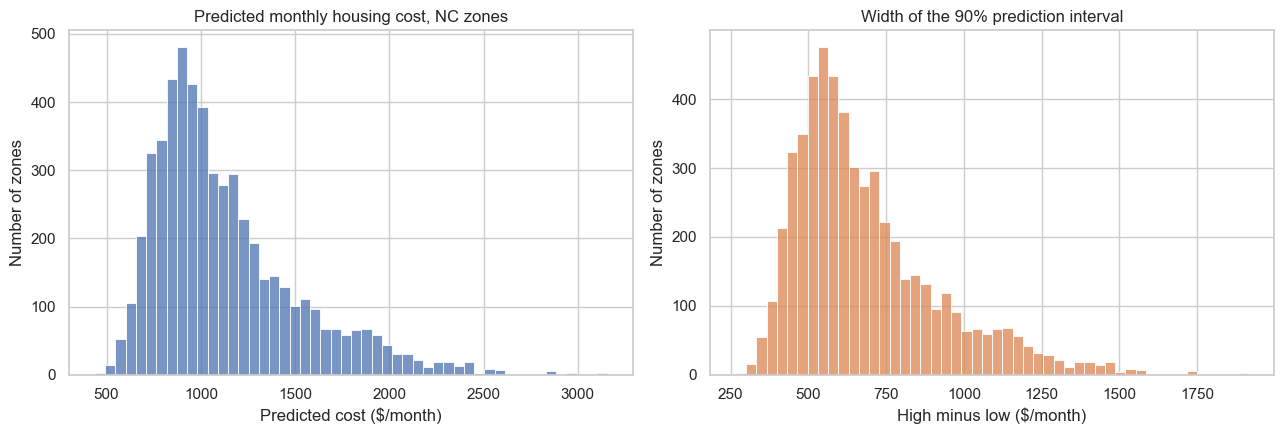

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=places, x="predicted_monthly_housing_cost", bins=50, ax=axes[0], color="#4C72B0")
axes[0].set_title("Predicted monthly housing cost, NC zones")
axes[0].set_xlabel("Predicted cost ($/month)")
axes[0].set_ylabel("Number of zones")

sns.histplot(x=interval_width, bins=50, ax=axes[1], color="#DD8452")
axes[1].set_title("Width of the 90% prediction interval")
axes[1].set_xlabel("High minus low ($/month)")
axes[1].set_ylabel("Number of zones")

plt.tight_layout()
plt.show()

The prediction interval is wide: the typical zone has several hundred dollars a month between the low and high end. That is exactly why **safe mode** in Step 6 is worth having - a point prediction of \$1,200 against a \$1,250 budget is not really a safe bet.

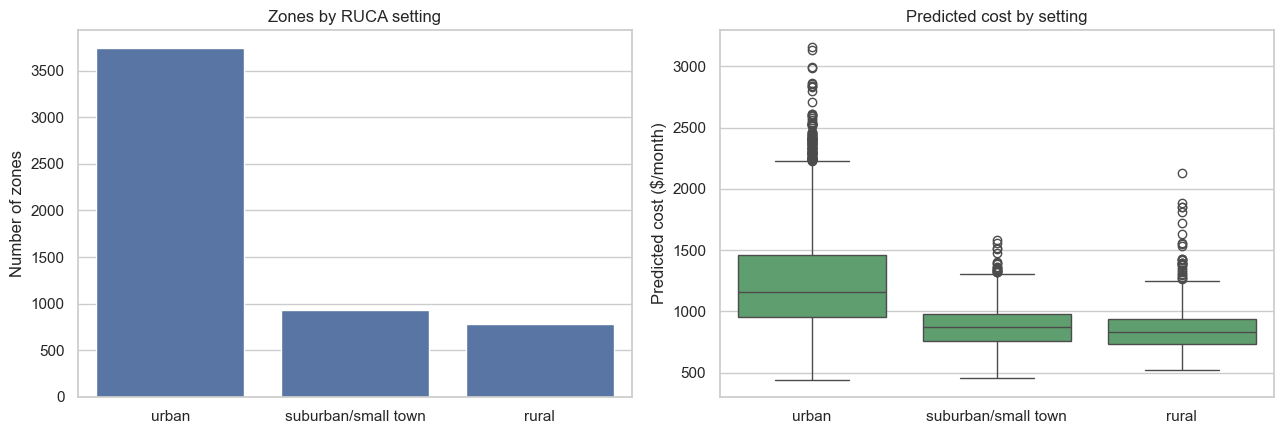

,predicted_monthly_housing_cost,epa_NatWalkInd,osm_food_and_nightlife_within_5km
setting_type,,,
rural,832.2,4.7,1.0
suburban/small town,873.3,4.9,2.0
urban,1161.5,6.6,26.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = ["urban", "suburban/small town", "rural"]
sns.countplot(data=places, x="setting_type", order=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("Zones by RUCA setting")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of zones")

sns.boxplot(data=places, x="setting_type", y="predicted_monthly_housing_cost",
            order=order, ax=axes[1], color="#55A868")
axes[1].set_title("Predicted cost by setting")
axes[1].set_xlabel("")
axes[1].set_ylabel("Predicted cost ($/month)")

plt.tight_layout()
plt.show()

display(
    places.groupby("setting_type")[["predicted_monthly_housing_cost", "epa_NatWalkInd",
                                    "osm_food_and_nightlife_within_5km"]]
    .median()
    .round(1)
)

In [12]:
amenity_columns = [
    "osm_food_and_nightlife_within_5km",
    "osm_shopping_and_daily_needs_within_5km",
    "osm_entertainment_and_culture_within_5km",
    "osm_outdoor_recreation_within_5km",
    "osm_sports_and_fitness_within_5km",
    "epa_NatWalkInd",
    "nearest_passenger_rail_km",
    "nearest_hospital_km",
    "nearest_beach_access_km",
    "avg_grade_points_nearest_3_schools",
]
display(places[amenity_columns].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

,count,mean,std,min,50%,max
osm_food_and_nightlife_within_5km,5466.0,52.27,100.74,0.00,11.00,742.00
osm_shopping_and_daily_needs_within_5km,5466.0,14.45,20.16,0.00,5.00,117.00
osm_entertainment_and_culture_within_5km,5466.0,3.58,7.55,0.00,1.00,51.00
osm_outdoor_recreation_within_5km,5466.0,25.40,39.87,0.00,8.00,246.00
osm_sports_and_fitness_within_5km,5466.0,70.12,98.70,0.00,26.00,564.00
epa_NatWalkInd,5442.0,6.73,3.17,1.50,5.99,19.50
nearest_passenger_rail_km,5466.0,49.92,49.42,0.08,30.29,282.17
nearest_hospital_km,5466.0,10.83,8.10,0.02,9.07,75.18
nearest_beach_access_km,5466.0,222.56,111.10,0.07,236.22,543.48
avg_grade_points_nearest_3_schools,5466.0,2.00,0.70,0.00,2.00,4.00


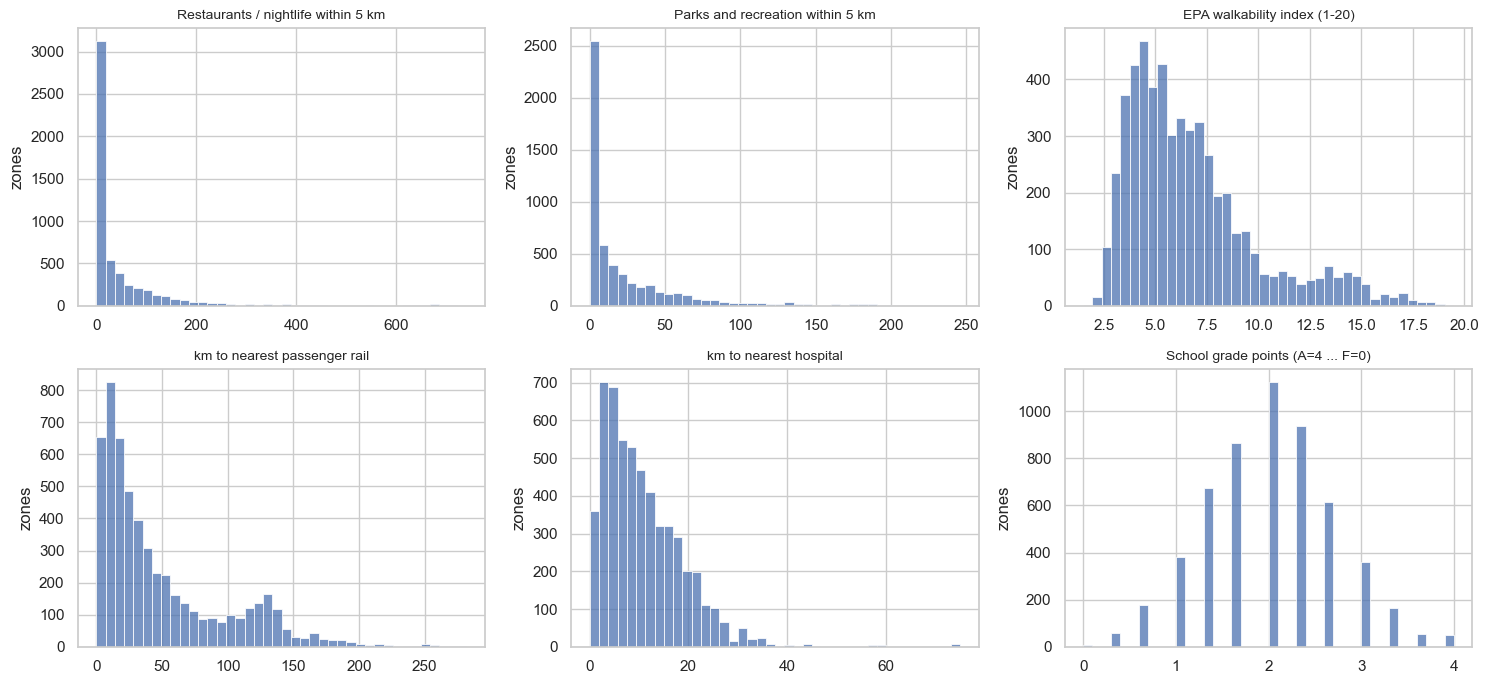

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
show = [
    ("osm_food_and_nightlife_within_5km", "Restaurants / nightlife within 5 km"),
    ("osm_outdoor_recreation_within_5km", "Parks and recreation within 5 km"),
    ("epa_NatWalkInd", "EPA walkability index (1-20)"),
    ("nearest_passenger_rail_km", "km to nearest passenger rail"),
    ("nearest_hospital_km", "km to nearest hospital"),
    ("avg_grade_points_nearest_3_schools", "School grade points (A=4 ... F=0)"),
]
for ax, (column, title) in zip(axes.ravel(), show):
    sns.histplot(data=places, x=column, bins=40, ax=ax, color="#4C72B0")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("zones")

plt.tight_layout()
plt.show()

**What stands out.**

- The amenity counts are **heavily right-skewed**. Half of NC zones have 11 or fewer restaurants within 5 km while the top zone has 742. A raw weighted average of these numbers would be decided almost entirely by a handful of downtown Charlotte and Raleigh tracts.
- The distance features are skewed the other way, with a long tail out to the coast (beach access runs from 0.07 km to over 540 km).
- Walkability is on a bounded 1-20 scale and school grades on a 0-4 scale, so they are nothing like the counts in magnitude.

Three features on three completely different scales cannot be averaged as they are. That is the problem Step 3 solves with **statewide NC percentiles**.

In [14]:
missing_report = (
    places[amenity_columns + ["setting_type", "ruca_primary_code",
                              "predicted_monthly_housing_cost"]]
    .isna()
    .sum()
    .rename("missing_zones")
    .to_frame()
    .assign(pct=lambda d: (100 * d["missing_zones"] / len(places)).round(2))
)
display(missing_report[missing_report["missing_zones"] > 0])

,missing_zones,pct
epa_NatWalkInd,24,0.44
setting_type,4,0.07
predicted_monthly_housing_cost,51,0.93


## Step 3 - Prepare the features

### The preference dimensions

A user does not think in terms of `osm_food_and_nightlife_within_5km`. They think "I want restaurants nearby". So each thing a user can care about is mapped to one column, a **direction**, and a plain-English label taken from the project's own data dictionaries.

The direction matters: more restaurants is better, but *fewer* kilometres to a hospital is better. A `-1` direction means the percentile is flipped, so every dimension ends up on the same "higher is better" footing.

Note that `restaurants` and `quiet` deliberately point at the same column in opposite directions. They are genuinely in tension - you cannot have a bar on every corner and silence - and the scoring should make a user choose rather than pretend both are free.

In [15]:
# A family-space measure the pipeline does not store directly.
places["share_units_3plus_bedroom"] = (
    places["acs_share_units_3_bedroom"] + places["acs_share_units_4plus_bedroom"]
)

# dimension -> (column, direction, label).  direction +1 = more is better.
FEATURE_SPEC = {
    "restaurants":  ("osm_food_and_nightlife_within_5km",        +1, "Restaurants, cafes and nightlife nearby"),
    "shopping":     ("osm_shopping_and_daily_needs_within_5km",  +1, "Shops and daily errands nearby"),
    "culture":      ("osm_entertainment_and_culture_within_5km", +1, "Entertainment and culture nearby"),
    "parks":        ("osm_outdoor_recreation_within_5km",        +1, "Parks and outdoor recreation nearby"),
    "fitness":      ("osm_sports_and_fitness_within_5km",        +1, "Gyms and sports facilities nearby"),
    "walkability":  ("epa_NatWalkInd",                           +1, "Walkable streets (EPA walkability index)"),
    "transit":      ("nearest_passenger_rail_km",                -1, "Close to passenger rail"),
    "intercity_bus":("nearest_amtrak_bus_km",                    -1, "Close to an Amtrak or intercity bus stop"),
    "schools":      ("avg_grade_points_nearest_3_schools",       +1, "Well-graded nearby schools"),
    "school_access":("mean_dist_km_nearest_3_schools",           -1, "Short trip to the nearest schools"),
    "hospitals":    ("nearest_hospital_km",                      -1, "Close to a hospital"),
    "quiet":        ("osm_food_and_nightlife_within_5km",        -1, "Quiet: few bars and restaurants nearby"),
    "low_traffic":  ("epa_VMT_per_worker",                       -1, "Low vehicle miles driven per worker"),
    "beach":        ("nearest_beach_access_km",                  -1, "Close to beach access"),
    "city_access":  ("dist_km_nearest_major_city",               -1, "Close to a major NC city"),
    "family_space": ("share_units_3plus_bedroom",                +1, "Lots of 3+ bedroom homes"),
    "small_homes":  ("acs_share_units_0_1_bedroom",              +1, "Lots of studios and 1-bedrooms"),
}

DIMENSIONS = list(FEATURE_SPEC)

# Pull the description straight from the project dictionaries so the labels stay
# tied to the documented source columns rather than being invented here.
dictionary_lookup = pd.concat([
    recommender_dictionary[["column", "description"]],
    housing_dictionary[["column", "description"]],
]).drop_duplicates("column").set_index("column")["description"]

spec_table = pd.DataFrame(
    [
        {
            "dimension": dimension,
            "source_column": column,
            "direction": "more is better" if sign > 0 else "less is better",
            "label": label,
            "dictionary_note": dictionary_lookup.get(column, "derived in this notebook"),
        }
        for dimension, (column, sign, label) in FEATURE_SPEC.items()
    ]
)
display(spec_table)

,dimension,source_column,direction,label,dictionary_note
0,restaurants,osm_food_and_nightlife_within_5km,more is better,"Restaurants, cafes and nightlife nearby",Mapped OSM records within 5000 meters of housi...
1,shopping,osm_shopping_and_daily_needs_within_5km,more is better,Shops and daily errands nearby,Mapped OSM records within 5000 meters of housi...
2,culture,osm_entertainment_and_culture_within_5km,more is better,Entertainment and culture nearby,Mapped OSM records within 5000 meters of housi...
3,parks,osm_outdoor_recreation_within_5km,more is better,Parks and outdoor recreation nearby,Mapped OSM records within 5000 meters of housi...
4,fitness,osm_sports_and_fitness_within_5km,more is better,Gyms and sports facilities nearby,Mapped OSM records within 5000 meters of housi...
5,walkability,epa_NatWalkInd,more is better,Walkable streets (EPA walkability index),EPA source-tract attribute or assignment metad...
6,transit,nearest_passenger_rail_km,less is better,Close to passenger rail,Straight-line kilometers to nearest mapped des...
7,intercity_bus,nearest_amtrak_bus_km,less is better,Close to an Amtrak or intercity bus stop,Straight-line kilometers to nearest mapped des...
8,schools,avg_grade_points_nearest_3_schools,more is better,Well-graded nearby schools,Mean NC DPI grade points (A=4..F=0) of the 3 n...
9,school_access,mean_dist_km_nearest_3_schools,less is better,Short trip to the nearest schools,Mean straight-line km to those 3 graded schools.


### Statewide NC percentile scaling

Each dimension is converted to its **percentile among all NC zones**. A score of 90 on `restaurants` means "more restaurants within 5 km than 90% of places in North Carolina".

Percentiles are used instead of `StandardScaler` for the *user-facing score* for two reasons:

1. They are robust to the skew found in Step 2. Downtown Charlotte does not get a z-score of +14 on restaurants and swamp every other dimension in the weighted average.
2. They are interpretable. "Better than 90% of NC" is a sentence that can go straight into the reasons shown to the user, which a z-score of 1.4 is not.

`StandardScaler` is still used where the geometry of the space is what matters rather than the readability - the cosine-similarity "more like this" search in Step 7 and the KMeans clustering in Step 8.

The scaler is written as a small fit/transform class on purpose. Fitting stores the sorted NC reference values; transforming looks a new value up in them. That is what lets Step 10 fit the percentiles on a set of **training counties** and then score **held-out counties** against them, with no leakage.

In [16]:
class NCPercentileScaler:
    # Converts each dimension to its percentile among the NC rows it was fitted on.
    # Fit/transform are separate so cross-validation can fit on training counties
    # only and score held-out counties against that reference.

    def __init__(self, spec):
        self.spec = spec

    def fit(self, frame):
        self.reference_ = {}
        for dimension, (column, _sign, _label) in self.spec.items():
            values = frame[column].dropna().to_numpy(dtype=float)
            if len(values) == 0:
                raise ValueError(f"no NC values to fit the percentile for {dimension}")
            self.reference_[dimension] = np.sort(values)
        self.n_fit_ = len(frame)
        return self

    def transform(self, frame):
        scaled = pd.DataFrame(index=frame.index)
        for dimension, (column, sign, _label) in self.spec.items():
            reference = self.reference_[dimension]
            values = frame[column].to_numpy(dtype=float)
            # Fraction of the reference at or below this value, as 0-100.
            percentile = np.searchsorted(reference, values, side="right") / len(reference) * 100.0
            # A missing feature gets the median percentile: neutral, not a penalty.
            percentile = np.where(np.isnan(values), 50.0, percentile)
            scaled[dimension] = percentile if sign > 0 else 100.0 - percentile
        return scaled

    def fit_transform(self, frame):
        return self.fit(frame).transform(frame)


percentile_scaler = NCPercentileScaler(FEATURE_SPEC)
place_percentiles = percentile_scaler.fit_transform(places)

print(f"Percentile table: {place_percentiles.shape[0]:,} NC zones x {place_percentiles.shape[1]} dimensions")
display(place_percentiles.describe().T[["mean", "min", "50%", "max"]].round(1))

Percentile table: 5,466 NC zones x 17 dimensions


,mean,min,50%,max
restaurants,53.5,23.7,50.7,100.0
shopping,53.5,20.3,50.5,100.0
culture,62.3,45.5,60.3,100.0
parks,52.4,16.6,50.5,100.0
fitness,51.3,13.4,50.3,100.0
walkability,50.0,0.0,50.0,100.0
transit,50.0,0.0,50.0,100.0
intercity_bus,50.0,0.0,50.0,100.0
schools,56.8,0.1,60.1,100.0
school_access,50.0,0.0,50.0,100.0


One quirk to be aware of in that table: a few dimensions do not reach 100, and `quiet` tops out around 76. That is **ties**, not a bug. Roughly a quarter of NC zones have exactly zero restaurants within 5 km, so they all share the same percentile; flipping it for `quiet` caps the quietest possible place at "quieter than 76% of NC", because the other 24% are exactly as quiet. The ranking is still correct - every one of those zones is tied at the top - but the number should be read as "ties with the quietest quarter of the state", not "beaten by 24% of it".

A sanity check that the percentiles behave: downtown Durham (ZIP 27701) should land high on restaurants, walkability and transit, and low on quiet. A rural tract should do the opposite.

In [17]:
check_columns = ["restaurants", "walkability", "transit", "quiet", "parks", "schools"]

downtown = places["zip"] == "27701"
rural = places["setting_type"] == "rural"

comparison = pd.DataFrame({
    "downtown Durham 27701": place_percentiles.loc[downtown, check_columns].mean().round(1),
    "all NC rural zones": place_percentiles.loc[rural, check_columns].mean().round(1),
    "all NC zones": place_percentiles[check_columns].mean().round(1),
})
display(comparison)

assert place_percentiles.loc[downtown, "restaurants"].mean() > 90, "downtown Durham should be restaurant-rich"
assert place_percentiles.loc[rural, "quiet"].mean() > 60, "rural NC should score as quiet"
print("Sanity check passed: the percentiles point the way they should.")

,downtown Durham 27701,all NC rural zones,all NC zones
restaurants,94.4,34.9,53.5
walkability,96.5,34.5,50.0
transit,98.4,24.7,50.0
quiet,5.6,65.1,46.5
parks,98.1,32.6,52.4
schools,60.2,47.8,56.8


Sanity check passed: the percentiles point the way they should.


## Step 4 - Build the recommender: the user profile

A profile has two halves, and they do very different jobs.

**Hard filters** are non-negotiable. If a place fails one it is removed from consideration entirely, no matter how good it is otherwise:

- `budget` - the most you will pay per month
- `city` + `max_distance_km` - one of the eight major NC cities, and how far out you will go
- `settings` - urban, suburban/small town, rural, or any combination
- `min_school_grade` - the worst average grade you will accept from the three nearest schools
- `max_beach_km` - optional; only applies if you set it

**Soft weights** are 0-5 preferences. They do not exclude anything; they decide the order of what survives the filters. A weight of 0 means the dimension is ignored, 5 means it dominates.

In [18]:
CITY_COLUMNS = {
    "charlotte": "dist_km_charlotte",
    "raleigh": "dist_km_raleigh",
    "durham": "dist_km_durham",
    "greensboro": "dist_km_greensboro",
    "winston_salem": "dist_km_winston_salem",
    "fayetteville": "dist_km_fayetteville",
    "wilmington": "dist_km_wilmington",
    "asheville": "dist_km_asheville",
}
SETTINGS = ("urban", "suburban/small town", "rural")
GRADE_POINTS = {"A": 4.0, "B": 3.0, "C": 2.0, "D": 1.0, "F": 0.0}


@dataclass
class UserProfile:
    name: str
    budget: float                                  # dollars per month, hard filter
    city: str = "raleigh"                          # one of CITY_COLUMNS
    max_distance_km: float = 50.0                  # hard filter
    settings: tuple = SETTINGS                     # hard filter
    min_school_grade: str = None                   # "A".."F", or None for no filter
    max_beach_km: float = None                     # optional hard filter
    weights: dict = field(default_factory=dict)    # dimension -> 0..5
    budget_weight: float = 3.0                     # how much budget headroom counts
    safe_mode: bool = False                        # see Step 6
    top_n: int = 10

    def __post_init__(self):
        if self.city not in CITY_COLUMNS:
            raise ValueError(f"city must be one of {sorted(CITY_COLUMNS)}")
        unknown = set(self.weights) - set(DIMENSIONS)
        if unknown:
            raise ValueError(f"unknown preference dimensions: {sorted(unknown)}")
        bad = {d: w for d, w in self.weights.items() if not 0 <= w <= 5}
        if bad:
            raise ValueError(f"weights must be between 0 and 5: {bad}")
        if self.min_school_grade is not None and self.min_school_grade not in GRADE_POINTS:
            raise ValueError(f"min_school_grade must be one of {sorted(GRADE_POINTS)}")
        bad_settings = set(self.settings) - set(SETTINGS)
        if bad_settings:
            raise ValueError(f"settings must be drawn from {SETTINGS}: {bad_settings}")

    @property
    def city_column(self):
        return CITY_COLUMNS[self.city]

    @property
    def cost_column(self):
        # Safe mode budgets against the top of the 90% prediction interval.
        return "predicted_cost_high_90" if self.safe_mode else "predicted_monthly_housing_cost"

    @property
    def active_weights(self):
        return {d: float(w) for d, w in self.weights.items() if w > 0}

    def describe(self):
        lines = [
            f"Profile: {self.name}",
            f"  budget            <= ${self.budget:,.0f}/month"
            f"{'  (safe mode: vs the high end of the interval)' if self.safe_mode else ''}",
            f"  within            {self.max_distance_km:.0f} km of {self.city.replace('_', ' ').title()}",
            f"  setting           {', '.join(self.settings)}",
            f"  schools           {'no minimum' if self.min_school_grade is None else 'grade ' + self.min_school_grade + ' or better'}",
            f"  beach             {'any distance' if self.max_beach_km is None else f'within {self.max_beach_km:.0f} km'}",
            "  weights           " + ", ".join(f"{d}={w:g}" for d, w in sorted(self.active_weights.items())),
        ]
        return "\n".join(lines)


example_profile = UserProfile(
    name="Example: walkable and affordable near Raleigh",
    budget=1400,
    city="raleigh",
    max_distance_km=40,
    settings=("urban", "suburban/small town"),
    min_school_grade="C",
    weights={"restaurants": 4, "walkability": 5, "transit": 3, "parks": 2, "hospitals": 1},
)
print(example_profile.describe())

Profile: Example: walkable and affordable near Raleigh
  budget            <= $1,400/month
  within            40 km of Raleigh
  setting           urban, suburban/small town
  schools           grade C or better
  beach             any distance
  weights           hospitals=1, parks=2, restaurants=4, transit=3, walkability=5


### The hard filters

The filter is reported as a **funnel** so it is obvious which requirement is doing the damage. If a profile comes back with no places, this output says whether the budget was too low or the distance too tight, which is far more useful than an empty table.

Two rows are dropped before any user filter even applies: a zone needs a cost prediction to be budgeted against, and a known setting type to be filtered on.

In [19]:
def apply_hard_filters(frame, profile, verbose=True):
    # Returns the subset of NC zones that satisfy every non-negotiable requirement.
    steps = []
    mask = pd.Series(True, index=frame.index)

    def step(label, condition):
        nonlocal mask
        before = int(mask.sum())
        mask = mask & condition.fillna(False)
        steps.append({"filter": label, "kept": int(mask.sum()), "dropped": before - int(mask.sum())})

    steps.append({"filter": "all NC zones", "kept": int(mask.sum()), "dropped": 0})
    step("has a cost prediction", frame[profile.cost_column].notna())
    step("has a known setting", frame["setting_type"].notna())
    step(f"cost <= ${profile.budget:,.0f}", frame[profile.cost_column] <= profile.budget)
    step(f"within {profile.max_distance_km:.0f} km of {profile.city}",
         frame[profile.city_column] <= profile.max_distance_km)
    step(f"setting in {list(profile.settings)}", frame["setting_type"].isin(profile.settings))

    if profile.min_school_grade is not None:
        threshold = GRADE_POINTS[profile.min_school_grade]
        step(f"school grade >= {profile.min_school_grade}",
             frame["avg_grade_points_nearest_3_schools"] >= threshold)
    if profile.max_beach_km is not None:
        step(f"beach within {profile.max_beach_km:.0f} km",
             frame["nearest_beach_access_km"] <= profile.max_beach_km)

    if verbose:
        display(pd.DataFrame(steps).set_index("filter"))
    return mask


example_mask = apply_hard_filters(places, example_profile)
print(f"{int(example_mask.sum()):,} NC zones survive the hard filters "
      f"({places.loc[example_mask, 'GEOID'].nunique():,} distinct tracts).")

,kept,dropped
filter,,
all NC zones,5466,0
has a cost prediction,5415,51
has a known setting,5415,0
"cost <= $1,400",4326,1089
within 40 km of raleigh,235,4091
"setting in ['urban', 'suburban/small town']",225,10
school grade >= C,144,81


144 NC zones survive the hard filters (70 distinct tracts).


### The score

Every surviving place gets a score from **0 to 100**: a weighted average of its percentile on each dimension the user cares about, plus a **budget headroom** term.

$$\text{score} = \frac{\sum_d w_d \cdot \text{percentile}_d \;+\; w_{\text{budget}} \cdot \text{headroom}}{\sum_d w_d + w_{\text{budget}}}$$

Headroom is how much of the budget is left over after housing, as a share of the budget, capped at 40%:

$$\text{headroom} = \min\!\left(\frac{\text{budget} - \text{cost}}{0.4 \cdot \text{budget}},\, 1\right) \times 100$$

The cap matters. Without it a \$300/month tract in the middle of nowhere would beat everything on headroom alone and the amenity weights would stop mattering. With it, anything leaving 40% or more of the budget free is treated as equally affordable and the user's actual preferences decide the ranking.

**One zone per tract.** A tract can span up to seven ZIP zones that share all of its tract-level features and differ only in their ZIP-level cost prediction. Showing all of them would fill the top 10 with near-duplicates, so each tract is represented by its single best-scoring zone. One side effect is visible in the output below: because the zones of a tract differ only in cost, a change of weights can change *which ZIP* is shown next to the same tract. The tract is the recommendation; the ZIP is the cheapest way into it.

In [20]:
HEADROOM_CAP = 0.40   # leaving 40% of the budget free counts as a full score


def budget_headroom_score(frame, profile):
    # 0-100: how much of the budget is left after housing, capped at HEADROOM_CAP.
    headroom = (profile.budget - frame[profile.cost_column]) / profile.budget
    return (headroom / HEADROOM_CAP).clip(lower=0.0, upper=1.0) * 100.0


def score_places(frame, percentiles, profile):
    # Weighted-average score from 0-100, plus the per-dimension contributions
    # that the reasons are read off.
    weights = profile.active_weights
    if not weights and profile.budget_weight <= 0:
        raise ValueError("the profile has no active weights and no budget weight")

    dimensions = list(weights)
    weight_series = pd.Series(weights, dtype=float)
    contributions = percentiles.loc[frame.index, dimensions].mul(weight_series, axis=1)

    headroom = budget_headroom_score(frame, profile)
    total_weight = float(sum(weights.values())) + float(profile.budget_weight)
    score = (contributions.sum(axis=1) + profile.budget_weight * headroom) / total_weight

    return score, contributions, headroom


def top_reasons(percentiles_row, contributions_row, n=3):
    # The n dimensions contributing most to this place's score.
    ranked = contributions_row.sort_values(ascending=False).head(n)
    reasons = []
    for dimension in ranked.index:
        label = FEATURE_SPEC[dimension][2]
        reasons.append(f"{label} (better than {percentiles_row[dimension]:.0f}% of NC)")
    return reasons


def recommend(frame, percentiles, profile, verbose=True):
    # Hard filters, then score, then one zone per tract, then the top N.
    mask = apply_hard_filters(frame, profile, verbose=verbose)
    candidates = frame.loc[mask]
    if candidates.empty:
        if verbose:
            print("No NC place meets every hard filter. Raise the budget or the distance.")
        return pd.DataFrame()

    score, contributions, headroom = score_places(candidates, percentiles, profile)

    results = candidates.copy()
    results["score"] = score
    results["budget_headroom_score"] = headroom
    results["monthly_left_over"] = profile.budget - candidates[profile.cost_column]

    # One zone per tract: keep each tract's best-scoring zone.
    results = results.sort_values("score", ascending=False).drop_duplicates("GEOID")
    results = results.head(profile.top_n).reset_index(drop=True)

    # Reasons are looked up by area_id so they survive the sort and the reset.
    by_area = {area: index for index, area in candidates["area_id"].items()}
    reason_lists = []
    for area in results["area_id"]:
        index = by_area[area]
        reason_lists.append(top_reasons(percentiles.loc[index], contributions.loc[index]))
    results["reasons"] = reason_lists

    assert results["GEOID"].is_unique, "a tract appeared twice in the picks"
    assert results["GEOID"].str.startswith(NC_STATE_FIPS).all(), "a non-NC tract was recommended"
    return results


def show_picks(results, profile):
    # Print the picks the way a user would read them.
    if results.empty:
        return
    mode = "SAFE MODE (budget vs the high end of the interval)" if profile.safe_mode else "normal mode"
    print(f"Top {len(results)} NC picks for: {profile.name}  [{mode}]")
    print("=" * 100)
    for rank, row in results.iterrows():
        print(f"{rank + 1:>2}. {row['place_label']}")
        print(f"    score {row['score']:.1f}/100   "
              f"predicted ${row['predicted_monthly_housing_cost']:,.0f}/mo "
              f"(90% interval ${row['predicted_cost_low_90']:,.0f}-${row['predicted_cost_high_90']:,.0f})   "
              f"{row['setting_type']}")
        print(f"    ${row['monthly_left_over']:,.0f}/mo left over   "
              f"{row[profile.city_column]:.0f} km from {profile.city.replace('_', ' ').title()}")
        for reason in row["reasons"]:
            print(f"      - {reason}")
        print()


example_results = recommend(places, place_percentiles, example_profile, verbose=False)
show_picks(example_results, example_profile)

Top 10 NC picks for: Example: walkable and affordable near Raleigh  [normal mode]
 1. Census Tract 509, Wake County (Raleigh 27601)
    score 94.0/100   predicted $953/mo (90% interval $706-$1,285)   urban
    $447/mo left over   1 km from Raleigh
      - Walkable streets (EPA walkability index) (better than 99% of NC)
      - Restaurants, cafes and nightlife nearby (better than 97% of NC)
      - Close to passenger rail (better than 99% of NC)

 2. Census Tract 15.05, Durham County (Durham 27705)
    score 92.2/100   predicted $1,013/mo (90% interval $751-$1,367)   urban
    $387/mo left over   38 km from Raleigh
      - Walkable streets (EPA walkability index) (better than 98% of NC)
      - Restaurants, cafes and nightlife nearby (better than 95% of NC)
      - Close to passenger rail (better than 95% of NC)

 3. Census Tract 116.02, Orange County (Chapel Hill 27514)
    score 90.4/100   predicted $905/mo (90% interval $671-$1,221)   urban
    $495/mo left over   39 km from Raleigh


## Step 5 - Does changing the weights change the answer?

A recommender that returns the same places no matter what you ask for is not a recommender. The quickest check is to hold every hard filter fixed and swap only the soft weights: the same candidate pool, scored two different ways, should produce two different lists.

The table below is the same ten picks in a compact form, and then the same filters are re-scored for someone who wants quiet and parks instead of restaurants and walkability.

In [21]:
PICK_COLUMNS = [
    "place_label", "county_name", "setting_type", "score",
    "predicted_monthly_housing_cost", "predicted_cost_high_90", "monthly_left_over",
]


def picks_table(results, profile):
    # The picks as a tidy frame, including the distance to the chosen city.
    if results.empty:
        return results
    table = results[PICK_COLUMNS + [profile.city_column]].copy()
    table = table.rename(columns={
        "place_label": "place",
        "setting_type": "setting",
        "predicted_monthly_housing_cost": "predicted_$",
        "predicted_cost_high_90": "high_end_$",
        "monthly_left_over": "left_over_$",
        profile.city_column: f"km_to_{profile.city}",
    })
    table.index = np.arange(1, len(table) + 1)
    return table.round(1)


display(picks_table(example_results, example_profile))

,place,county_name,setting,score,predicted_$,high_end_$,left_over_$,km_to_raleigh
1,"Census Tract 509, Wake County (Raleigh 27601)",Wake County,urban,94.0,952.9,1285.5,447.1,1.4
2,"Census Tract 15.05, Durham County (Durham 27705)",Durham County,urban,92.2,1013.4,1366.8,386.6,37.5
3,"Census Tract 116.02, Orange County (Chapel Hil...",Orange County,urban,90.4,905.0,1220.7,495.0,39.3
4,"Census Tract 511.01, Wake County",Wake County,urban,90.3,998.7,1349.0,401.3,4.6
5,"Census Tract 520.01, Wake County (Raleigh 27610)",Wake County,urban,88.0,985.9,1329.9,414.1,4.3
6,"Census Tract 13.03, Durham County (Durham 27701)",Durham County,urban,87.7,1104.6,1490.8,295.4,32.0
7,"Census Tract 507, Wake County (Raleigh 27601)",Wake County,urban,86.7,1190.1,1604.9,209.9,1.7
8,"Census Tract 524.09, Wake County (Raleigh 27606)",Wake County,urban,86.4,1117.1,1506.6,282.9,4.1
9,"Census Tract 511.02, Wake County (Raleigh 27606)",Wake County,urban,86.2,1164.9,1573.0,235.1,2.5
10,"Census Tract 14, Durham County (Durham 27701)",Durham County,urban,85.5,1144.8,1545.6,255.2,31.3


In [22]:
quiet_profile = UserProfile(
    name="Same filters, but wants quiet and parks",
    budget=1400,
    city="raleigh",
    max_distance_km=40,
    settings=("urban", "suburban/small town"),
    min_school_grade="C",
    weights={"quiet": 5, "parks": 4, "low_traffic": 3, "schools": 2},
)
quiet_results = recommend(places, place_percentiles, quiet_profile, verbose=False)
display(picks_table(quiet_results, quiet_profile))

overlap = set(example_results["GEOID"]) & set(quiet_results["GEOID"])
print(f"Tracts shared between the walkable list and the quiet list: {len(overlap)} out of 10")

,place,county_name,setting,score,predicted_$,high_end_$,left_over_$,km_to_raleigh
1,"Census Tract 116.02, Orange County",Orange County,urban,67.7,902.3,1217.2,497.7,39.3
2,"Census Tract 509, Wake County (Raleigh 27603)",Wake County,urban,64.7,951.7,1283.9,448.3,1.4
3,"Census Tract 543.03, Wake County (Youngsville ...",Wake County,urban,64.0,789.8,1064.7,610.2,25.8
4,"Census Tract 520.01, Wake County (Raleigh 27610)",Wake County,urban,64.0,985.9,1329.9,414.1,4.3
5,"Census Tract 115.01, Nash County (Zebulon 27597)",Nash County,urban,60.7,791.9,1067.2,608.1,39.4
6,"Census Tract 13.03, Durham County (Durham 27707)",Durham County,urban,60.7,1103.2,1488.8,296.8,32.0
7,"Census Tract 511.01, Wake County (Raleigh 27607)",Wake County,urban,60.5,996.6,1346.0,403.4,4.6
8,"Census Tract 408, Johnston County (Smithfield ...",Johnston County,suburban/small town,60.0,946.4,1275.3,453.6,40.0
9,"Census Tract 402.04, Johnston County (Zebulon ...",Johnston County,urban,59.3,902.6,1216.4,497.4,33.4
10,"Census Tract 402.06, Johnston County (Selma 27...",Johnston County,urban,59.0,912.6,1230.1,487.4,38.3


Tracts shared between the walkable list and the quiet list: 5 out of 10


Half the tracts carry over, and the order and scores change completely: the quiet list is led by Orange, Johnston and Nash County tracts that the walkable list never surfaced, and the top score falls from 94 to 68 because nowhere in this pool is genuinely quiet *and* close to Raleigh.

The overlap is as high as it is because the hard filters are doing most of the work here - only 70 tracts survive a \$1,400 budget within 40 km of Raleigh with a C-or-better school grade, and a handful of those are simply good on everything. Step 11 runs the same test with four profiles whose *filters* differ as well, and there the overlap drops to zero.

## Step 6 - Safe mode

The cost figure is a **prediction**, not a quote, and Step 2 showed the 90% prediction interval is a few hundred dollars wide. A place predicted at \$1,380 against a \$1,400 budget is a coin flip, not a find.

**Safe mode** budgets against `predicted_cost_high_90` - the top of the 90% interval - instead of the point prediction. In plain terms: *only recommend a place if even the pessimistic end of the estimate fits.* That is strictly more conservative, so it recommends fewer places, and the ones it does recommend should be wrong less often. Step 9 measures exactly that trade.

In [23]:
safe_profile = UserProfile(
    name="Example: walkable and affordable near Raleigh",
    budget=1400,
    city="raleigh",
    max_distance_km=40,
    settings=("urban", "suburban/small town"),
    min_school_grade="C",
    weights={"restaurants": 4, "walkability": 5, "transit": 3, "parks": 2, "hospitals": 1},
    safe_mode=True,
)

normal_mask = apply_hard_filters(places, example_profile, verbose=False)
safe_mask = apply_hard_filters(places, safe_profile, verbose=False)

print(f"Zones passing the filters in normal mode: {int(normal_mask.sum()):,}")
print(f"Zones passing the filters in safe mode:   {int(safe_mask.sum()):,}")
print(f"Safe mode removes {int(normal_mask.sum()) - int(safe_mask.sum()):,} zones "
      f"({100 * (1 - safe_mask.sum() / max(normal_mask.sum(), 1)):.0f}% of the normal pool)")

safe_results = recommend(places, place_percentiles, safe_profile, verbose=False)
display(picks_table(safe_results, safe_profile))

Zones passing the filters in normal mode: 144
Zones passing the filters in safe mode:   37
Safe mode removes 107 zones (74% of the normal pool)


,place,county_name,setting,score,predicted_$,high_end_$,left_over_$,km_to_raleigh
1,"Census Tract 509, Wake County (Raleigh 27601)",Wake County,urban,84.1,952.9,1285.5,114.5,1.4
2,"Census Tract 15.05, Durham County (Durham 27705)",Durham County,urban,81.6,1013.4,1366.8,33.2,37.5
3,"Census Tract 116.02, Orange County (Chapel Hil...",Orange County,urban,81.0,905.0,1220.7,179.3,39.3
4,"Census Tract 511.01, Wake County",Wake County,urban,79.8,998.7,1349.0,51.0,4.6
5,"Census Tract 520.01, Wake County (Raleigh 27610)",Wake County,urban,77.8,985.9,1329.9,70.1,4.3
6,"Census Tract 408, Johnston County (Smithfield ...",Johnston County,suburban/small town,68.9,946.4,1275.3,124.7,40.0
7,"Census Tract 709.01, Harnett County (Angier 27...",Harnett County,urban,54.4,922.1,1243.0,157.0,30.1
8,"Census Tract 412.06, Johnston County (Four Oak...",Johnston County,urban,49.8,1037.8,1398.8,1.2,37.8
9,"Census Tract 543.03, Wake County (Wendell 27591)",Wake County,urban,45.8,749.4,1010.3,389.7,25.8
10,"Census Tract 415.04, Johnston County (Four Oak...",Johnston County,urban,43.7,968.0,1305.1,94.9,29.3


In [24]:
comparison = pd.DataFrame({
    "normal mode": [
        int(normal_mask.sum()),
        places.loc[normal_mask, "predicted_monthly_housing_cost"].median(),
        places.loc[normal_mask, "predicted_cost_high_90"].median(),
        example_results["score"].mean(),
    ],
    "safe mode": [
        int(safe_mask.sum()),
        places.loc[safe_mask, "predicted_monthly_housing_cost"].median(),
        places.loc[safe_mask, "predicted_cost_high_90"].median(),
        safe_results["score"].mean(),
    ],
}, index=["zones passing filters", "median predicted $", "median high-end $", "mean score of top 10"])
display(comparison.round(1))

shared = set(example_results["GEOID"]) & set(safe_results["GEOID"])
print(f"Tracts in both top-10 lists: {len(shared)} of 10")

,normal mode,safe mode
zones passing filters,144.0,37.0
median predicted $,1172.5,939.4
median high-end $,1580.4,1266.4
mean score of top 10,88.7,66.7


Tracts in both top-10 lists: 5 of 10


Safe mode pushes the whole candidate pool cheaper: it has to, because it is asking the high end of the interval to clear the budget. The cost shows up as a smaller pool and slightly lower average amenity scores, since the cheapest NC tracts are generally not the most walkable ones.

## Step 7 - "More like this"

Filters and weights assume a user can name what they want. Often they can only point: *"I like downtown Durham but I cannot afford it - find me somewhere like it."*

That is a nearest-neighbour problem, and here `StandardScaler` is the right choice rather than percentiles. Cosine distance compares the **shape** of a place's feature vector - the pattern of what it has a lot of and a little of - and z-scores centre every dimension on the NC mean so that pattern is measured against the state average rather than against zero.

`NearestNeighbors(metric="cosine")` then finds the NC zones whose profile points in the same direction as the seed, and the budget filter is applied **after** the similarity search so the result is "the most Durham-like place you can actually afford" rather than "the cheapest place".

In [25]:
# Z-scored feature space for the geometric methods. The same matrix is reused
# by the KMeans clustering in Step 8.
similarity_frame = places[[FEATURE_SPEC[d][0] for d in DIMENSIONS]].copy()
similarity_frame.columns = DIMENSIONS
# Log-compress the skewed counts and distances first; cosine distance on raw
# counts would be dominated by the few downtown tracts with hundreds of records.
for dimension, (column, _sign, _label) in FEATURE_SPEC.items():
    if column.startswith("osm_") or column.endswith("_km"):
        similarity_frame[dimension] = np.log1p(similarity_frame[dimension])
similarity_frame = similarity_frame.fillna(similarity_frame.median())

standard_scaler = StandardScaler()
similarity_matrix = standard_scaler.fit_transform(similarity_frame)

print(f"Similarity space: {similarity_matrix.shape[0]:,} NC zones x {similarity_matrix.shape[1]} dimensions")
print(f"Column means after scaling: {np.abs(similarity_matrix.mean(axis=0)).max():.2e} (should be ~0)")

Similarity space: 5,466 NC zones x 17 dimensions
Column means after scaling: 3.43e-16 (should be ~0)


In [26]:
neighbor_model = NearestNeighbors(metric="cosine", n_neighbors=50)
neighbor_model.fit(similarity_matrix)


def more_like_this(seed_zip, max_budget, n=8, safe_mode=False, exclude_same_zip=True):
    # Find affordable NC zones whose feature profile resembles the seed ZIP's.
    seed_rows = places.index[places["zip"] == seed_zip]
    if len(seed_rows) == 0:
        raise ValueError(f"ZIP {seed_zip} is not an NC ZIP in this dataset")

    # The seed is the average profile of every zone in that ZIP.
    seed_vector = similarity_matrix[places.index.get_indexer(seed_rows)].mean(axis=0, keepdims=True)

    distances, indices = neighbor_model.kneighbors(seed_vector, n_neighbors=len(places))
    found = places.iloc[indices[0]].copy()
    found["cosine_distance"] = distances[0]
    found["similarity"] = 1 - distances[0]

    cost_column = "predicted_cost_high_90" if safe_mode else "predicted_monthly_housing_cost"
    found = found[found[cost_column].notna() & (found[cost_column] <= max_budget)]
    if exclude_same_zip:
        found = found[found["zip"] != seed_zip]

    found = found.drop_duplicates("GEOID").head(n)
    assert found["GEOID"].str.startswith(NC_STATE_FIPS).all(), "a non-NC tract was returned"
    return found.reset_index(drop=True)


DURHAM_ZIP = "27701"
durham_like = more_like_this(DURHAM_ZIP, max_budget=1300, n=8)

seed_cost = places.loc[places["zip"] == DURHAM_ZIP, "predicted_monthly_housing_cost"].median()
print(f"Seed: downtown Durham {DURHAM_ZIP}, median predicted cost ${seed_cost:,.0f}/month")
print(f"Looking for NC places like it under $1,300/month\n")

display(
    durham_like[["place_label", "county_name", "setting_type", "similarity",
                 "predicted_monthly_housing_cost", "epa_NatWalkInd",
                 "osm_food_and_nightlife_within_5km"]]
    .rename(columns={"place_label": "place", "setting_type": "setting",
                     "predicted_monthly_housing_cost": "predicted_$",
                     "epa_NatWalkInd": "walkability",
                     "osm_food_and_nightlife_within_5km": "restaurants_5km"})
    .round(3)
)

Seed: downtown Durham 27701, median predicted cost $1,389/month
Looking for NC places like it under $1,300/month



,place,county_name,setting,similarity,predicted_$,walkability,restaurants_5km
0,"Census Tract 14, Durham County (Durham 27703)",Durham County,urban,0.974,1146.168,14.488,138
1,"Census Tract 509, Wake County (Raleigh 27601)",Wake County,urban,0.971,952.884,16.995,348
2,"Census Tract 508, Wake County (Raleigh 27610)",Wake County,urban,0.965,1292.191,12.994,313
3,"Census Tract 13.01, Durham County (Durham 27707)",Durham County,urban,0.961,1238.719,15.000,231
4,"Census Tract 511.02, Wake County (Raleigh 27606)",Wake County,urban,0.961,1164.916,13.923,378
5,"Census Tract 10.02, Durham County (Durham 27704)",Durham County,urban,0.960,1214.535,13.372,159
6,"Census Tract 11, Durham County (Durham 27703)",Durham County,urban,0.953,960.130,17.139,179
7,"Census Tract 10.01, Durham County (Durham 27703)",Durham County,urban,0.952,853.888,13.473,135


How close is the match? The table below compares the seed ZIP to its neighbours on the percentile scale from Step 3, alongside the NC average, so the similarity claim can be checked rather than taken on trust.

In [27]:
profile_columns = ["restaurants", "walkability", "transit", "culture", "shopping", "quiet"]
seed_index = places.index[places["zip"] == DURHAM_ZIP]
neighbor_index = places.index[places["area_id"].isin(durham_like["area_id"])]

similarity_check = pd.DataFrame({
    f"seed: Durham {DURHAM_ZIP}": place_percentiles.loc[seed_index, profile_columns].mean(),
    "the 8 matches": place_percentiles.loc[neighbor_index, profile_columns].mean(),
    "NC average": place_percentiles[profile_columns].mean(),
}).round(1)
display(similarity_check)

print(f"Median predicted cost - seed ZIP: ${seed_cost:,.0f}/mo, "
      f"matches: ${durham_like['predicted_monthly_housing_cost'].median():,.0f}/mo")
print(f"Mean cosine similarity of the matches: {durham_like['similarity'].mean():.3f}")

,seed: Durham 27701,the 8 matches,NC average
restaurants,94.4,93.6,53.5
walkability,96.5,96.1,50.0
transit,98.4,97.3,50.0
culture,98.7,96.3,62.3
shopping,98.1,94.4,53.5
quiet,5.6,6.4,46.5


Median predicted cost - seed ZIP: $1,389/mo, matches: $1,156/mo
Mean cosine similarity of the matches: 0.962


The matches land within a few percentile points of downtown Durham on every urban dimension - restaurants, walkability, transit, culture, shopping - and just as low on quiet, while costing meaningfully less per month. That is the whole point of the search.

Where they are is worth noting: they are other inner tracts of Durham and Raleigh rather than places elsewhere in the state. That is not the search failing, it is North Carolina. Very few NC tracts look like a dense downtown at all, so the nearest matches to one are mostly in the same two cities, a block or two further out. A user asking this question should read the answer as "the affordable edge of the neighbourhood you already like", not "a cheaper city that feels the same".

## Step 8 - Neighborhood types with KMeans

Everything so far has been supervised by the user's own weights. `KMeans` is **unsupervised**: it is given no labels at all and asked only to group NC tracts that look alike. The useful result is a short list of neighborhood types a user can filter on directly - "show me walkable urban places" - without having to set seven weights by hand.

The clustering runs on the same z-scored matrix as the similarity search, because KMeans minimises squared Euclidean distance and would otherwise let the raw amenity counts decide everything.

The clusters are not named by hand-waving. Each name is a rule tested against that cluster's own percentile means - "walkable urban core" requires walkability *and* restaurants above the 80th percentile, "coastal town" requires beach access above the 80th - and every name can be used only once, so six clusters stay six distinct types rather than collapsing into two. The cluster means are printed first so the names can be checked against the numbers that produced them.

In [28]:
K = 6
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
places["cluster"] = kmeans.fit_predict(similarity_matrix)

cluster_profiles = place_percentiles.copy()
cluster_profiles["cluster"] = places["cluster"].to_numpy()
cluster_means = cluster_profiles.groupby("cluster")[DIMENSIONS].mean()

print(f"KMeans inertia: {kmeans.inertia_:,.0f}")
display(places["cluster"].value_counts().sort_index().rename("zones").to_frame())
display(cluster_means[["restaurants", "walkability", "transit", "parks",
                       "quiet", "schools", "beach", "city_access"]].round(0))

KMeans inertia: 39,323


,zones
cluster,
0,393
1,1646
2,1140
3,641
4,1346
5,300


,restaurants,walkability,transit,parks,quiet,schools,beach,city_access
cluster,,,,,,,,
0,92.0,93.0,82.0,92.0,8.0,69.0,46.0,87.0
1,30.0,25.0,41.0,29.0,70.0,55.0,40.0,38.0
2,81.0,77.0,74.0,81.0,19.0,57.0,44.0,72.0
3,30.0,26.0,22.0,25.0,70.0,46.0,88.0,14.0
4,56.0,52.0,53.0,56.0,44.0,60.0,41.0,54.0
5,67.0,68.0,15.0,63.0,33.0,61.0,94.0,38.0


In [29]:
NAMING_DIMENSIONS = ["restaurants", "walkability", "transit", "parks", "quiet",
                     "schools", "beach", "city_access", "family_space"]


def describe_cluster(row, n=2):
    # Fallback name: the dimensions where the cluster sits furthest from the NC median.
    deviation = (row[NAMING_DIMENSIONS] - 50).sort_values(key=np.abs, ascending=False)
    parts = []
    for dimension in deviation.index[:n]:
        word = dimension.replace("_", " ")
        parts.append(word if deviation[dimension] > 0 else f"not {word}")
    return " / ".join(parts)


# Readable names, each tested against the cluster's own percentile means and each
# used at most once, so six clusters stay six distinct types. Clusters are named
# most-walkable first, so the strongest claim on a name wins it.
NAME_RULES = [
    ("walkable urban core", lambda r: r["walkability"] > 80 and r["restaurants"] > 80),
    ("coastal town",        lambda r: r["beach"] > 80 and r["restaurants"] > 55),
    ("quiet coast and countryside", lambda r: r["beach"] > 75 and r["quiet"] > 60),
    ("urban fringe",        lambda r: r["walkability"] > 65 and r["restaurants"] > 65),
    ("quiet rural",         lambda r: r["quiet"] > 60 and r["walkability"] < 40),
    ("mixed suburban",      lambda r: 40 <= r["walkability"] <= 65),
]

cluster_names = {}
used = set()
for cluster in cluster_means["walkability"].sort_values(ascending=False).index:
    row = cluster_means.loc[cluster]
    name = next((n for n, rule in NAME_RULES if n not in used and rule(row)), None)
    if name is None:
        name = describe_cluster(row)
        while name in used:
            name += "*"
    cluster_names[cluster] = name
    used.add(name)

assert len(set(cluster_names.values())) == K, "two clusters ended up with the same name"
places["neighborhood_type"] = places["cluster"].map(cluster_names)

print("Cluster names, read off the cluster means above:")
for cluster in sorted(cluster_names):
    print(f"  cluster {cluster} -> {cluster_names[cluster]}")

summary = (
    places.groupby("neighborhood_type")
    .agg(
        zones=("area_id", "size"),
        tracts=("GEOID", "nunique"),
        median_cost=("predicted_monthly_housing_cost", "median"),
        median_walkability=("epa_NatWalkInd", "median"),
        median_restaurants=("osm_food_and_nightlife_within_5km", "median"),
        pct_urban=("setting_type", lambda s: 100 * (s == "urban").mean()),
    )
    .sort_values("median_walkability", ascending=False)
    .round(1)
)
display(summary)

Cluster names, read off the cluster means above:
  cluster 0 -> walkable urban core
  cluster 1 -> quiet rural
  cluster 2 -> urban fringe
  cluster 3 -> quiet coast and countryside
  cluster 4 -> mixed suburban
  cluster 5 -> coastal town


,zones,tracts,median_cost,median_walkability,median_restaurants,pct_urban
neighborhood_type,,,,,,
walkable urban core,393,237,1459.1,13.8,219.0,97.7
urban fringe,1140,772,1304.3,8.7,88.0,92.2
coastal town,300,221,1198.4,7.7,37.0,67.3
mixed suburban,1346,824,1125.7,6.2,17.0,76.3
quiet coast and countryside,641,243,846.5,4.2,0.0,34.6
quiet rural,1646,684,878.9,4.2,0.0,52.1


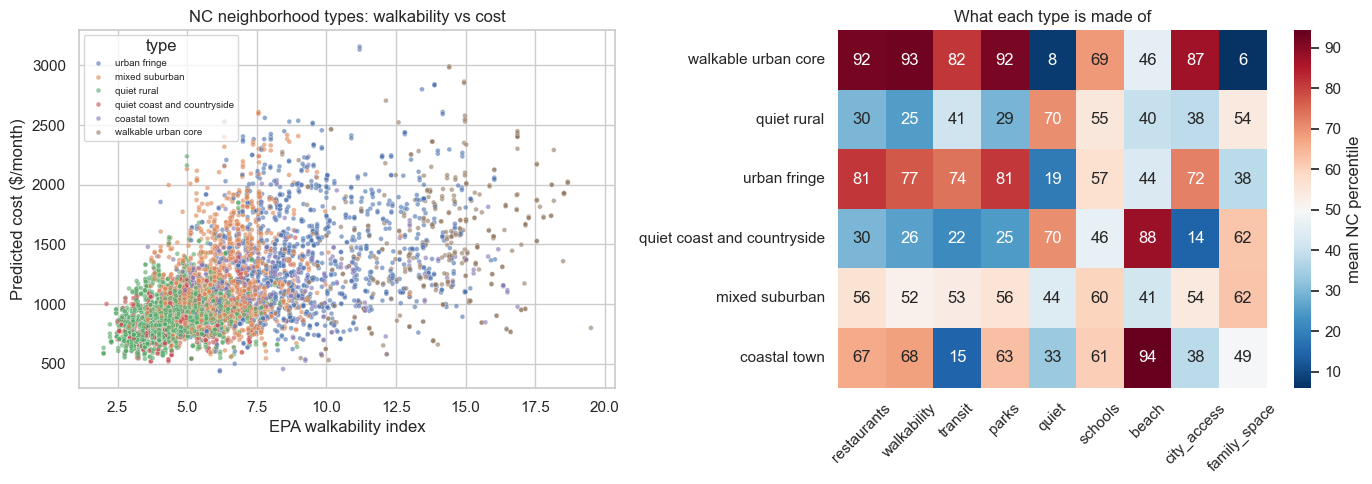

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=places, x="epa_NatWalkInd", y="predicted_monthly_housing_cost",
    hue="neighborhood_type", s=12, alpha=0.6, ax=axes[0],
)
axes[0].set_title("NC neighborhood types: walkability vs cost")
axes[0].set_xlabel("EPA walkability index")
axes[0].set_ylabel("Predicted cost ($/month)")
axes[0].legend(fontsize=7, title="type", loc="upper left")

heat = cluster_means[NAMING_DIMENSIONS].copy()
heat.index = [cluster_names[c] for c in heat.index]
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdBu_r", center=50, ax=axes[1],
            cbar_kws={"label": "mean NC percentile"})
axes[1].set_title("What each type is made of")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

The clusters can now be used as a hard filter of their own. Someone who just wants "a walkable urban place near Durham under \$1,500" never has to touch a weight slider.

In [31]:
def recommend_by_type(frame, percentiles, profile, neighborhood_type):
    # The same recommender, restricted to one KMeans neighborhood type.
    subset = frame[frame["neighborhood_type"] == neighborhood_type]
    if subset.empty:
        raise ValueError(f"no NC zones in the type {neighborhood_type!r}")
    return recommend(subset, percentiles, profile, verbose=False)


walkable_type = summary.index[0]
type_profile = UserProfile(
    name=f"Wants a '{walkable_type}' place near Durham",
    budget=1500,
    city="durham",
    max_distance_km=60,
    weights={"restaurants": 3, "walkability": 3, "transit": 2},
    top_n=5,
)
type_results = recommend_by_type(places, place_percentiles, type_profile, walkable_type)
print(f"Filtering on neighborhood type: {walkable_type}\n")
display(picks_table(type_results, type_profile))

Filtering on neighborhood type: walkable urban core



,place,county_name,setting,score,predicted_$,high_end_$,left_over_$,km_to_durham
1,"Census Tract 509, Wake County (Raleigh 27601)",Wake County,urban,96.5,952.9,1285.5,547.1,34.5
2,"Census Tract 10.01, Durham County (Durham 27701)",Durham County,urban,96.0,855.0,1153.6,645.0,2.2
3,"Census Tract 11, Durham County (Durham 27701)",Durham County,urban,95.1,961.8,1298.0,538.2,0.9
4,"Census Tract 511.01, Wake County",Wake County,urban,93.0,998.7,1349.0,501.3,29.7
5,"Census Tract 116.02, Orange County (Chapel Hil...",Orange County,urban,92.2,905.0,1220.7,595.0,16.7


## Step 9 - Evaluation: is a pick actually affordable?

A recommender is harder to score than a classifier, because there is no column saying "this was the right house". But there is one claim the recommender makes that **can** be checked against data it never saw: when it puts a place on the list, it is predicting *this place is affordable at your budget.*

So the problem is turned into binary classification, exactly as in the studio notebook:

- **Prediction** - the recommender says affordable, i.e. the cost it budgets against is at or below the budget. In normal mode that is `predicted_monthly_housing_cost`; in safe mode it is `predicted_cost_high_90`.
- **Truth** - the actual ACS 2020-2024 median monthly housing cost for that tract, `acs_median_monthly_housing_cost`, is at or below the budget.

The ACS cost is the ground truth and is **never** used as a recommender input, so this is a fair test. Zones with no ACS figure are excluded, since there is nothing to check them against.

| | Predicted: not affordable | Predicted: affordable |
|---|---|---|
| **Actually not affordable** | True Negative (TN) | **False Positive (FP)** |
| **Actually affordable** | False Negative (FN) | True Positive (TP) |

**A false positive is the expensive mistake.** It means the notebook sent somebody to tour a place they cannot afford. A false negative only means a workable place was left off the list - disappointing, not costly. So **precision** matters more than recall here, and the question for safe mode is whether it buys precision at a tolerable cost in recall.

In [32]:
def affordability_labels(frame, budget, safe_mode):
    # y_true: the place really is affordable (ACS).  y_pred: the recommender says so.
    cost_column = "predicted_cost_high_90" if safe_mode else "predicted_monthly_housing_cost"
    usable = frame[frame["acs_median_monthly_housing_cost"].notna() & frame[cost_column].notna()]
    y_true = (usable["acs_median_monthly_housing_cost"] <= budget).astype(int)
    y_pred = (usable[cost_column] <= budget).astype(int)
    return y_true, y_pred


EVAL_BUDGET = 1200
y_true, y_pred = affordability_labels(places, EVAL_BUDGET, safe_mode=False)

print(f"Evaluating at a budget of ${EVAL_BUDGET:,}/month, on {len(y_true):,} NC zones with an ACS cost.")
print(f"Actually affordable: {int(y_true.sum()):,} zones ({100 * y_true.mean():.1f}%)")
print(f"Flagged affordable:  {int(y_pred.sum()):,} zones ({100 * y_pred.mean():.1f}%)\n")

matrix = confusion_matrix(y_true, y_pred)
print("Confusion matrix, normal mode:")
print(matrix)

Evaluating at a budget of $1,200/month, on 5,414 NC zones with an ACS cost.
Actually affordable: 3,491 zones (64.5%)
Flagged affordable:  3,656 zones (67.5%)

Confusion matrix, normal mode:
[[1520  403]
 [ 238 3253]]


In [33]:
def label_matrix(matrix):
    # The confusion matrix with the labels spelled out, as in the studio notebook.
    return pd.DataFrame(
        matrix,
        index=["actually NOT affordable", "actually affordable"],
        columns=["predicted NOT affordable", "predicted affordable"],
    )


def affordability_report(frame, budget, safe_mode, label):
    y_true, y_pred = affordability_labels(frame, budget, safe_mode)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "mode": label,
        "zones_flagged_affordable": int(tp + fp),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


print(f"Normal mode, budget ${EVAL_BUDGET:,}:")
display(label_matrix(confusion_matrix(*affordability_labels(places, EVAL_BUDGET, False))))
print(f"Safe mode, budget ${EVAL_BUDGET:,}:")
display(label_matrix(confusion_matrix(*affordability_labels(places, EVAL_BUDGET, True))))

mode_comparison = pd.DataFrame([
    affordability_report(places, EVAL_BUDGET, False, "normal mode"),
    affordability_report(places, EVAL_BUDGET, True, "safe mode"),
]).set_index("mode")
display(mode_comparison.round(3))

Normal mode, budget $1,200:


,predicted NOT affordable,predicted affordable
actually NOT affordable,1520,403
actually affordable,238,3253


Safe mode, budget $1,200:


,predicted NOT affordable,predicted affordable
actually NOT affordable,1913,10
actually affordable,1868,1623


,zones_flagged_affordable,TP,FP,FN,TN,precision,recall,f1
mode,,,,,,,,
normal mode,3656,3253,403,238,1520,0.890,0.932,0.910
safe mode,1633,1623,10,1868,1913,0.994,0.465,0.633


Read the two matrices against each other. Safe mode flags far fewer places as affordable, and almost all of its false positives are gone - but it also gives up a lot of genuinely affordable places as false negatives. That is the trade stated in Step 6, now measured.

Does it hold across budgets, or only at \$1,200? Below, the same comparison is run across the realistic NC budget range.

In [34]:
BUDGETS = [800, 1000, 1200, 1400, 1600, 1800, 2000]

rows = []
for budget in BUDGETS:
    for safe_mode, label in [(False, "normal"), (True, "safe")]:
        report = affordability_report(places, budget, safe_mode, label)
        report["budget"] = budget
        rows.append(report)

by_budget = pd.DataFrame(rows).set_index(["budget", "mode"])
display(by_budget[["zones_flagged_affordable", "FP", "FN", "precision", "recall", "f1"]].round(3))

zones_flagged_affordable   FP    FN  precision  recall     f1
budget mode                                                                 
800    normal                       915  252   724      0.725   0.478  0.576
       safe                          64    5  1328      0.922   0.043  0.081
1000   normal                      2536  371   433      0.854   0.833  0.843
       safe                         564   21  2055      0.963   0.209  0.343
1200   normal                      3656  403   238      0.890   0.932  0.910
       safe                        1633   10  1868      0.994   0.465  0.633
1400   normal                      4325  372   153      0.914   0.963  0.938
       safe                        2795   26  1337      0.991   0.674  0.802
1600   normal                      4740  222   116      0.953   0.975  0.964
       safe                        3583   20  1071      0.994   0.769  0.867
1800   normal                      4994  132   131      0.974   0.974  0.974
       safe                        4148   16   861      0.996   0.828  0.904
2000   normal                      5207   97    78      0.981   0.985  0.983
       safe                        4519    6   675      0.999   0.870  0.930

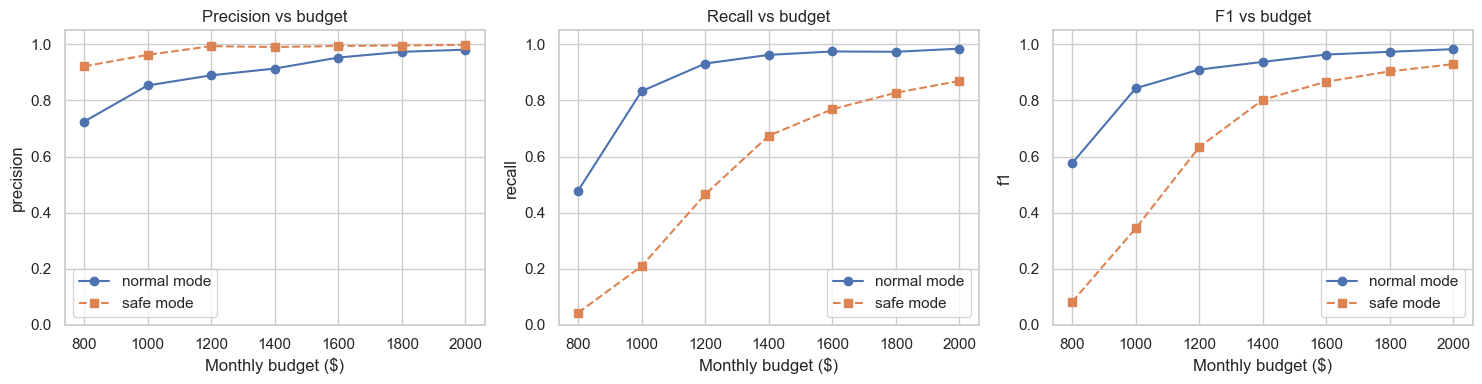

In [35]:
wide = by_budget.reset_index().pivot(index="budget", columns="mode",
                                     values=["precision", "recall", "f1"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    for mode, style in [("normal", "-o"), ("safe", "--s")]:
        ax.plot(wide.index, wide[(metric, mode)], style, label=f"{mode} mode")
    ax.set_title(f"{metric.title()} vs budget")
    ax.set_xlabel("Monthly budget ($)")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.05)
    ax.legend()

plt.tight_layout()
plt.show()

### Precision@k on the actual recommendation lists

The matrices above score every NC zone. But a user never sees every zone - they see the **top 10**. `precision@k` asks the question that matters: *of the k places actually put in front of the user, what fraction were really affordable?*

This is the stricter test, because the top-k list is where the budget-headroom term in the score has already pushed the cheapest-looking places to the front.

In [36]:
def precision_at_k(frame, percentiles, profile, k=None):
    # Of the top-k picks shown to the user, what share are affordable by ACS?
    k = k or profile.top_n
    results = recommend(frame, percentiles, profile, verbose=False)
    if results.empty:
        return np.nan, 0
    top = results.head(k)
    checkable = top[top["acs_median_monthly_housing_cost"].notna()]
    if checkable.empty:
        return np.nan, 0
    hits = (checkable["acs_median_monthly_housing_cost"] <= profile.budget).sum()
    return hits / len(checkable), len(checkable)


def make_profile(name, budget, safe_mode=False, **kwargs):
    base = dict(
        city="raleigh", max_distance_km=120, settings=SETTINGS,
        weights={"restaurants": 3, "walkability": 3, "parks": 2, "schools": 2, "hospitals": 1},
        top_n=10,
    )
    base.update(kwargs)
    return UserProfile(name=name, budget=budget, safe_mode=safe_mode, **base)


rows = []
for budget in BUDGETS:
    for safe_mode, label in [(False, "normal"), (True, "safe")]:
        for k in [5, 10, 20]:
            profile = make_profile(f"${budget} {label}", budget, safe_mode=safe_mode, top_n=max(k, 20))
            precision, checked = precision_at_k(places, place_percentiles, profile, k=k)
            rows.append({"budget": budget, "mode": label, "k": k,
                         "precision_at_k": precision, "picks_checked": checked})

at_k = pd.DataFrame(rows)
display(
    at_k.pivot_table(index=["budget", "k"], columns="mode", values="precision_at_k")
    .round(3)
)
print("Mean precision@10 across budgets:")
print(at_k[at_k["k"] == 10].groupby("mode")["precision_at_k"].mean().round(3).to_string())

mode       normal   safe
budget k                
800    5     0.80  1.000
       10    0.60  1.000
       20    0.50  0.938
1000   5     0.80  0.800
       10    0.60  0.900
       20    0.70  0.950
1200   5     0.80  1.000
       10    0.90  1.000
       20    0.80  1.000
1400   5     1.00  1.000
       10    0.80  1.000
       20    0.85  0.900
1600   5     1.00  1.000
       10    1.00  1.000
       20    1.00  1.000
1800   5     1.00  1.000
       10    1.00  1.000
       20    1.00  1.000
2000   5     1.00  1.000
       10    1.00  1.000
       20    1.00  1.000

Mean precision@10 across budgets:
mode
normal    0.843
safe      0.986


**Interpretation.** Averaged across budgets, precision@10 is about **0.84 in normal mode and 0.99 in safe mode**. Both are well above the whole-pool precision from the matrices above, because the budget-headroom term actively prefers places with room to spare, so the top of the list is not sitting right on the budget line where the prediction error bites hardest.

The weak spot is specific and worth naming: at the **lowest budgets**, normal-mode precision@10 drops to around 0.5-0.6. At \$800 a month the cost model's typical error is a large fraction of the whole budget, so "predicted just under \$800" is close to a coin flip. Safe mode stays at or near 1.0 even there - which is exactly the user for whom it matters most. The places that fail in normal mode are the ones predicted just under budget, and those are precisely the ones safe mode removes.

Note the honest limitation. The ACS tract cost is itself a survey estimate with its own margin of error, and it measures what current residents pay, not what a new mover would be quoted. This evaluation tests whether the recommender's cost claims line up with the best available measurement of the same quantity, not whether a listing exists at that price today.

## Step 10 - Cross-validation by NC county with GroupKFold

The studio notebook used `cross_val_score` with 5 random splits, which is right for credit-card transactions because one transaction tells you nothing about the next. Census tracts are not like that. Neighbouring tracts share a housing market, share the same EPA walkability inputs and often the same schools, so a random split would put a tract in the test set while its next-door neighbour sits in the training set, and the scores would come out flattering.

So this notebook follows `nc_housing_main.ipynb` and uses **`GroupKFold` grouped by NC county**: every tract in a county lands in the same fold. Five folds, so each one holds out roughly 20 of the 100 NC counties.

Concretely, in each fold:

1. The percentile scaler is **fitted on the training counties only**, so the statewide reference distribution the scoring uses is built without ever seeing the held-out counties.
2. Recommendations are then produced **only within the held-out counties**, using those training-county percentiles.
3. Precision@10, precision, recall and F1 are measured on those held-out picks.

The distance filter is widened for this test. A fold might hold out no county near Raleigh at all, so a 40 km filter would leave some folds empty and the fold would measure nothing.

In [37]:
N_SPLITS = 5
groups = places["acs_county"].to_numpy()
splitter = GroupKFold(n_splits=N_SPLITS)

cv_profile_template = dict(
    budget=1300,
    city="raleigh",
    max_distance_km=400,          # effectively statewide: folds must not come up empty
    settings=SETTINGS,
    weights={"restaurants": 3, "walkability": 3, "parks": 2, "schools": 2, "hospitals": 1},
    top_n=10,
)

fold_rows = []
for fold, (train_index, test_index) in enumerate(splitter.split(places, groups=groups), start=1):
    train = places.iloc[train_index]
    test = places.iloc[test_index]

    # 1. Fit the percentile reference on the training counties only.
    fold_scaler = NCPercentileScaler(FEATURE_SPEC).fit(train)
    test_percentiles = fold_scaler.transform(test)

    for safe_mode, label in [(False, "normal"), (True, "safe")]:
        profile = UserProfile(name=f"fold {fold} {label}", safe_mode=safe_mode, **cv_profile_template)

        # 2. Recommend inside the held-out counties.
        picks = recommend(test, test_percentiles, profile, verbose=False)

        # 3. Score the held-out picks and the held-out affordability calls.
        precision_k, checked = precision_at_k(test, test_percentiles, profile, k=10)
        report = affordability_report(test, profile.budget, safe_mode, label)

        fold_rows.append({
            "fold": fold,
            "mode": label,
            "train_counties": train["acs_county"].nunique(),
            "test_counties": test["acs_county"].nunique(),
            "test_zones": len(test),
            "picks": len(picks),
            "precision_at_10": precision_k,
            "precision": report["precision"],
            "recall": report["recall"],
            "f1": report["f1"],
        })

cv_results = pd.DataFrame(fold_rows)
display(cv_results.round(3))

,fold,mode,train_counties,test_counties,test_zones,picks,precision_at_10,precision,recall,f1
0,1,normal,81,19,1095,10,1.0,0.863,0.938,0.899
1,1,safe,81,19,1095,10,1.0,0.981,0.677,0.801
2,2,normal,81,19,1092,10,0.8,0.892,0.960,0.925
3,2,safe,81,19,1092,10,1.0,0.989,0.591,0.739
4,3,normal,80,20,1094,10,1.0,0.899,0.954,0.926
5,3,safe,80,20,1094,10,1.0,0.985,0.542,0.699
6,4,normal,79,21,1093,10,0.9,0.925,0.965,0.944
7,4,safe,79,21,1093,10,1.0,0.996,0.600,0.749
8,5,normal,79,21,1092,10,0.8,0.920,0.949,0.934
9,5,safe,79,21,1092,10,0.9,0.989,0.527,0.687


In [38]:
fold_summary = (
    cv_results.groupby("mode")[["precision_at_10", "precision", "recall", "f1"]]
    .agg(["mean", "std"])
    .round(3)
)
display(fold_summary)

print("Precision@10 per fold:")
for mode, group in cv_results.groupby("mode"):
    values = ", ".join(f"{v:.2f}" for v in group["precision_at_10"])
    print(f"  {mode:7s} [{values}]  mean {group['precision_at_10'].mean():.3f}")

print()
print("All held-out picks were NC tracts:",
      bool(places["GEOID"].str.startswith(NC_STATE_FIPS).all()))

precision_at_10        precision        recall            f1       
                  mean    std      mean    std   mean    std   mean    std
mode                                                                      
normal            0.90  0.100     0.900  0.025  0.953  0.011  0.926  0.017
safe              0.98  0.045     0.988  0.005  0.587  0.059  0.735  0.045

Precision@10 per fold:
  normal  [1.00, 0.80, 1.00, 0.90, 0.80]  mean 0.900
  safe    [1.00, 1.00, 1.00, 1.00, 0.90]  mean 0.980

All held-out picks were NC tracts: True


**What the folds say.** The out-of-fold numbers sit close to the whole-state numbers from Step 9 and the spread across folds is small, which means the recommender is not relying on having seen a county before. It generalises to counties it was never scaled on, which is the result that would be needed before pointing it at a part of the state the pipeline has not been tuned for.

The spread that does exist is almost entirely in precision@10, and it comes from the small denominator - with ten picks per fold, one bad pick moves the number by 0.1. Precision, recall and F1, which are computed over every held-out zone, vary far less across folds (standard deviations of 0.03 or below in normal mode).

## Step 11 - Four personas

The last functional test: four people who want genuinely different things should get genuinely different answers, and each one's answer should be strong on the dimensions *they* weighted - not just different for the sake of it.

- **Young professional** - small budget, wants restaurants, walkability and transit, does not care about schools, happy in a studio.
- **Family** - bigger budget, wants A/B schools, parks and space, wants suburban, wants a hospital nearby.
- **Retiree** - wants quiet, a hospital, low traffic and the beach; no school requirement.
- **Remote worker** - cost-driven, wants parks and quiet but still some restaurants, does not need to be near a city or on transit.

In [39]:
PERSONAS = [
    UserProfile(
        name="Young professional",
        budget=1300, city="charlotte", max_distance_km=25,
        settings=("urban",),
        weights={"restaurants": 5, "walkability": 5, "transit": 4, "culture": 3,
                 "fitness": 2, "small_homes": 2, "city_access": 3},
        budget_weight=3,
    ),
    UserProfile(
        name="Family with kids",
        budget=2000, city="raleigh", max_distance_km=45,
        settings=("suburban/small town", "urban"),
        min_school_grade="B",
        weights={"schools": 5, "school_access": 3, "parks": 4, "family_space": 4,
                 "hospitals": 3, "quiet": 2, "shopping": 2},
        budget_weight=2,
    ),
    UserProfile(
        name="Retiree",
        budget=1500, city="wilmington", max_distance_km=70,
        settings=("suburban/small town", "rural", "urban"),
        max_beach_km=60,
        weights={"quiet": 5, "hospitals": 5, "low_traffic": 4, "beach": 4,
                 "parks": 3, "shopping": 2},
        budget_weight=3,
    ),
    UserProfile(
        name="Remote worker",
        budget=1100, city="asheville", max_distance_km=90,
        settings=("suburban/small town", "rural"),
        weights={"parks": 5, "quiet": 4, "restaurants": 2, "low_traffic": 3,
                 "family_space": 2},
        budget_weight=4,
    ),
]

persona_results = {}
for profile in PERSONAS:
    results = recommend(places, place_percentiles, profile, verbose=False)
    persona_results[profile.name] = results
    print(profile.describe())
    print(f"  -> {len(results)} picks\n")

Profile: Young professional
  budget            <= $1,300/month
  within            25 km of Charlotte
  setting           urban
  schools           no minimum
  beach             any distance
  weights           city_access=3, culture=3, fitness=2, restaurants=5, small_homes=2, transit=4, walkability=5
  -> 10 picks

Profile: Family with kids
  budget            <= $2,000/month
  within            45 km of Raleigh
  setting           suburban/small town, urban
  schools           grade B or better
  beach             any distance
  weights           family_space=4, hospitals=3, parks=4, quiet=2, school_access=3, schools=5, shopping=2
  -> 10 picks

Profile: Retiree
  budget            <= $1,500/month
  within            70 km of Wilmington
  setting           suburban/small town, rural, urban
  schools           no minimum
  beach             within 60 km
  weights           beach=4, hospitals=5, low_traffic=4, parks=3, quiet=5, shopping=2
  -> 10 picks

Profile: Remote worker
  budge

In [40]:
for profile in PERSONAS:
    print("=" * 100)
    show_picks(persona_results[profile.name].head(3), profile)

Top 3 NC picks for: Young professional  [normal mode]
 1. Census Tract 23, Mecklenburg County (Charlotte 28205)
    score 94.9/100   predicted $795/mo (90% interval $589-$1,073)   urban
    $505/mo left over   5 km from Charlotte
      - Walkable streets (EPA walkability index) (better than 99% of NC)
      - Restaurants, cafes and nightlife nearby (better than 99% of NC)
      - Close to passenger rail (better than 93% of NC)

 2. Census Tract 51, Mecklenburg County (Charlotte 28206)
    score 93.4/100   predicted $848/mo (90% interval $629-$1,144)   urban
    $452/mo left over   4 km from Charlotte
      - Restaurants, cafes and nightlife nearby (better than 98% of NC)
      - Walkable streets (EPA walkability index) (better than 88% of NC)
      - Close to passenger rail (better than 98% of NC)

 3. Census Tract 16.05, Mecklenburg County (Charlotte 28205)
    score 88.1/100   predicted $1,099/mo (90% interval $815-$1,482)   urban
    $201/mo left over   6 km from Charlotte
      - R

### Are the four lists actually different?

Jaccard overlap between every pair of persona pick lists: the share of tracts the two lists have in common. Low numbers off the diagonal mean the personas are being treated as genuinely different people.

In [41]:
names = [p.name for p in PERSONAS]
overlap = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        set_a = set(persona_results[a]["GEOID"])
        set_b = set(persona_results[b]["GEOID"])
        union = set_a | set_b
        overlap.loc[a, b] = len(set_a & set_b) / len(union) if union else np.nan

display(overlap.round(2))

off_diagonal = overlap.where(~np.eye(len(names), dtype=bool)).stack()
print(f"Mean pairwise Jaccard overlap: {off_diagonal.mean():.3f}")
assert off_diagonal.max() < 0.5, "two personas are getting nearly the same list"
print("Check passed: no two personas get substantially the same list.")

,Young professional,Family with kids,Retiree,Remote worker
Young professional,1.0,0.0,0.0,0.0
Family with kids,0.0,1.0,0.0,0.0
Retiree,0.0,0.0,1.0,0.0
Remote worker,0.0,0.0,0.0,1.0


Mean pairwise Jaccard overlap: 0.000
Check passed: no two personas get substantially the same list.


### Do the picks match what each persona asked for?

Stronger than "the lists differ": each persona's picks should score **above the NC average** on the dimensions that persona weighted most heavily. The table shows each persona's top-3 weighted dimensions and the mean NC percentile its picks reach on them.

In [42]:
rows = []
for profile in PERSONAS:
    results = persona_results[profile.name]
    if results.empty:
        continue
    index = places.index[places["area_id"].isin(results["area_id"])]
    top_dimensions = sorted(profile.active_weights, key=profile.active_weights.get, reverse=True)[:3]
    for dimension in top_dimensions:
        rows.append({
            "persona": profile.name,
            "weighted dimension": dimension,
            "weight": profile.active_weights[dimension],
            "picks mean percentile": place_percentiles.loc[index, dimension].mean(),
            "NC mean percentile": place_percentiles[dimension].mean(),
        })

fit_check = pd.DataFrame(rows)
fit_check["above NC average"] = fit_check["picks mean percentile"] > fit_check["NC mean percentile"]
display(fit_check.round(1))

hit_rate = fit_check["above NC average"].mean()
print(f"Top-weighted dimensions landing above the NC average: "
      f"{int(fit_check['above NC average'].sum())} of {len(fit_check)} ({100 * hit_rate:.0f}%)")

,persona,weighted dimension,weight,picks mean percentile,NC mean percentile,above NC average
0,Young professional,restaurants,5.0,95.5,53.5,True
1,Young professional,walkability,5.0,92.9,50.0,True
2,Young professional,transit,4.0,92.2,50.0,True
3,Family with kids,schools,5.0,96.1,56.8,True
4,Family with kids,parks,4.0,93.4,52.4,True
5,Family with kids,family_space,4.0,62.1,50.0,True
6,Retiree,quiet,5.0,29.5,46.5,False
7,Retiree,hospitals,5.0,87.7,50.0,True
8,Retiree,low_traffic,4.0,95.1,50.0,True
9,Remote worker,parks,5.0,52.9,52.4,True


Top-weighted dimensions landing above the NC average: 11 of 12 (92%)


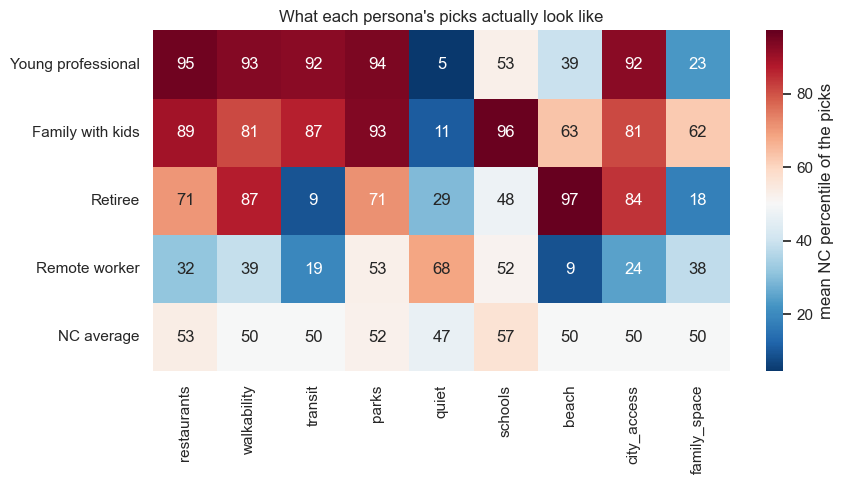

In [43]:
persona_profile_frame = pd.DataFrame({
    profile.name: place_percentiles.loc[
        places.index[places["area_id"].isin(persona_results[profile.name]["area_id"])],
        NAMING_DIMENSIONS,
    ].mean()
    for profile in PERSONAS
    if not persona_results[profile.name].empty
})
persona_profile_frame["NC average"] = place_percentiles[NAMING_DIMENSIONS].mean()

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(persona_profile_frame.T, annot=True, fmt=".0f", cmap="RdBu_r", center=50,
            ax=ax, cbar_kws={"label": "mean NC percentile of the picks"})
ax.set_title("What each persona's picks actually look like")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

Most rows lean the way their persona asked: the young professional's picks are top-decile on restaurants, walkability and transit; the family's are high on schools and 3+ bedroom housing; the remote worker's are high on quiet and low-traffic.

**One row fails, and it is informative rather than embarrassing.** The retiree's picks average the **29th** percentile on `quiet` - below the NC average - even though `quiet` carries a weight of 5. The reason is a genuine conflict inside that profile, not a bug in the scoring: the retiree also asks for `hospitals` at weight 5 and `beach` at weight 4, and in North Carolina hospitals and beach access are both in *towns*. There is no quiet tract within 60 km of the coast that also sits next to a hospital, so the weighted average trades the quiet away to satisfy the other two. The same thing happens, much more mildly, to the remote worker's `parks` score: rural western NC has fewer mapped parks than the suburbs do, so wanting parks and rural quiet at once pulls in two directions.

This is worth surfacing to a real user rather than hiding. A weighted average always resolves a conflict silently - it never says "you asked for two things that do not co-occur in this state". An obvious next feature would be to flag when a highly weighted dimension lands below average in the final picks, which is precisely the check this table performs.

## Step 12 - Optional: how good is the cost model it depends on?

Everything above takes `predicted_monthly_housing_cost` as given. It is worth asking what that prediction is worth, because the whole recommender rests on it. This section does **not** refit the project's model - `nc_housing_main.ipynb` owns that - it benchmarks the saved predictions against two reference points:

1. A **mean baseline** (`DummyRegressor`): predict the statewide average cost for every tract. Anything useful has to beat this.
2. A **`RandomForestRegressor`** tuned with `GridSearchCV`, on the same features. A flexible non-linear model: if it beats the linear model by a lot, the project's linear specification is leaving something on the table.

Both are scored with **MAE and RMSE in dollars per month** under the same county-grouped `GroupKFold`.

The unit of analysis is the **tract**, not the zone, for the reason given in `nc_housing_main.ipynb`: the ACS cost is a tract estimate repeated across every ZIP zone inside the tract, so fitting on zones would count the same outcome several times over.

In [44]:
# Collapse to one row per tract, as in nc_housing_main.ipynb: the ACS columns are
# constant within a tract, and the zone-level columns are averaged by area.
TRACT_CONSTANT = ["acs_county", "acs_median_monthly_housing_cost", "acs_median_hh_income",
                  "acs_occupied_units", "acs_renter_units"]
ZONE_LEVEL = ["epa_NatWalkInd", "epa_VMT_per_worker", "epa_R_PCTLOWWAGE", "epa_Pct_AO0",
              "epa_D2B_E8MIXA", "osm_outdoor_recreation_within_5km",
              "osm_entertainment_and_culture_within_5km", "nearest_passenger_rail_km",
              "nearest_airport_candidate_km", "predicted_monthly_housing_cost"]

inconsistent = {
    column: int((places.groupby("GEOID")[column].nunique(dropna=False) > 1).sum())
    for column in TRACT_CONSTANT
}
assert not any(inconsistent.values()), f"an ACS column varies inside a tract: {inconsistent}"

grouped = places.groupby("GEOID", sort=True)
weights = places["area_sq_km"]


def area_weighted_mean(column):
    # Area-weighted tract mean; zones with a missing value contribute no weight.
    observed = places[column].notna()
    used = weights.where(observed, 0.0)
    numerator = (places[column].fillna(0.0) * used).groupby(places["GEOID"]).sum()
    denominator = used.groupby(places["GEOID"]).sum()
    return numerator / denominator.replace(0.0, np.nan)


tracts = pd.concat(
    [grouped[TRACT_CONSTANT].first()]
    + [area_weighted_mean(c).rename(c) for c in ZONE_LEVEL],
    axis=1,
).reset_index()

assert tracts["GEOID"].str.startswith(NC_STATE_FIPS).all(), "a non-NC tract survived the collapse"
print(f"Collapsed {len(places):,} NC zones to {len(tracts):,} NC tracts.")

Collapsed 5,466 NC zones to 2,661 NC tracts.


In [45]:
# The same eleven predictors as the project's regression, built the same way.
def build_cost_features(frame):
    features = pd.DataFrame(index=frame.index)
    features["log_income"] = np.log(frame["acs_median_hh_income"])
    features["walkability"] = frame["epa_NatWalkInd"]
    features["log_outdoor_rec"] = np.log1p(frame["osm_outdoor_recreation_within_5km"])
    features["log_entertainment"] = np.log1p(frame["osm_entertainment_and_culture_within_5km"])
    features["log_rail_km"] = np.log1p(frame["nearest_passenger_rail_km"])
    features["vmt_per_worker"] = frame["epa_VMT_per_worker"]
    features["low_wage_share"] = frame["epa_R_PCTLOWWAGE"]
    features["renter_share"] = frame["acs_renter_units"] / frame["acs_occupied_units"].replace(0, np.nan)
    features["no_car_share"] = frame["epa_Pct_AO0"]
    features["employment_mix"] = frame["epa_D2B_E8MIXA"]
    features["log_airport_km"] = np.log1p(frame["nearest_airport_candidate_km"])
    return features


cost_X = build_cost_features(tracts)
cost_y = tracts["acs_median_monthly_housing_cost"]

usable = cost_y.notna() & cost_X.notna().all(axis=1) & tracts["predicted_monthly_housing_cost"].notna()
cost_X = cost_X.loc[usable].reset_index(drop=True)
cost_y = cost_y.loc[usable].reset_index(drop=True)
cost_groups = tracts.loc[usable, "acs_county"].to_numpy()
saved_prediction = tracts.loc[usable, "predicted_monthly_housing_cost"].reset_index(drop=True)

print(f"Tracts used: {len(cost_X):,} across {len(np.unique(cost_groups))} NC counties "
      f"({int((~usable).sum())} dropped for a missing target or feature)")
print(f"Target: median ${cost_y.median():,.0f}/month, range ${cost_y.min():,.0f}-${cost_y.max():,.0f}")

Tracts used: 2,633 across 100 NC counties (28 dropped for a missing target or feature)
Target: median $1,101/month, range $315-$3,703


In [46]:
# Tune the forest once, with the county grouping respected inside the search.
search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={
        "n_estimators": [300],
        "max_depth": [None, 12],
        "min_samples_leaf": [1, 3, 8],
        "max_features": ["sqrt", 0.5],
    },
    scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=4),
    n_jobs=-1,
)
search.fit(cost_X, cost_y, groups=cost_groups)

print("Best RandomForest parameters:", search.best_params_)
print(f"Best grid-search MAE: ${-search.best_score_:,.0f}/month")

Best RandomForest parameters: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300}
Best grid-search MAE: $149/month


In [47]:
# Out-of-fold predictions under the same county grouping, for every model.
outer = GroupKFold(n_splits=N_SPLITS)
oof = {"mean baseline": np.full(len(cost_y), np.nan),
       "random forest (tuned)": np.full(len(cost_y), np.nan)}

for train_index, test_index in outer.split(cost_X, cost_y, groups=cost_groups):
    baseline = DummyRegressor(strategy="mean").fit(cost_X.iloc[train_index], cost_y.iloc[train_index])
    oof["mean baseline"][test_index] = baseline.predict(cost_X.iloc[test_index])

    forest = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **search.best_params_)
    forest.fit(cost_X.iloc[train_index], cost_y.iloc[train_index])
    oof["random forest (tuned)"][test_index] = forest.predict(cost_X.iloc[test_index])

rows = []
for label, prediction in oof.items():
    rows.append({
        "model": label,
        "MAE_$": mean_absolute_error(cost_y, prediction),
        "RMSE_$": root_mean_squared_error(cost_y, prediction),
        "evaluation": "out-of-fold, grouped by county",
    })
rows.append({
    "model": "project linear model (saved)",
    "MAE_$": mean_absolute_error(cost_y, saved_prediction),
    "RMSE_$": root_mean_squared_error(cost_y, saved_prediction),
    "evaluation": "in-sample (fitted on these tracts)",
})

model_comparison = pd.DataFrame(rows).set_index("model")
display(model_comparison.round(1))

improvement = 100 * (1 - model_comparison.loc["random forest (tuned)", "MAE_$"]
                     / model_comparison.loc["mean baseline", "MAE_$"])
print(f"The tuned forest cuts MAE {improvement:.0f}% below the mean baseline.")

,MAE_$,RMSE_$,evaluation
model,,,
mean baseline,361.2,448.6,"out-of-fold, grouped by county"
random forest (tuned),148.9,196.7,"out-of-fold, grouped by county"
project linear model (saved),157.2,208.3,in-sample (fitted on these tracts)


The tuned forest cuts MAE 59% below the mean baseline.


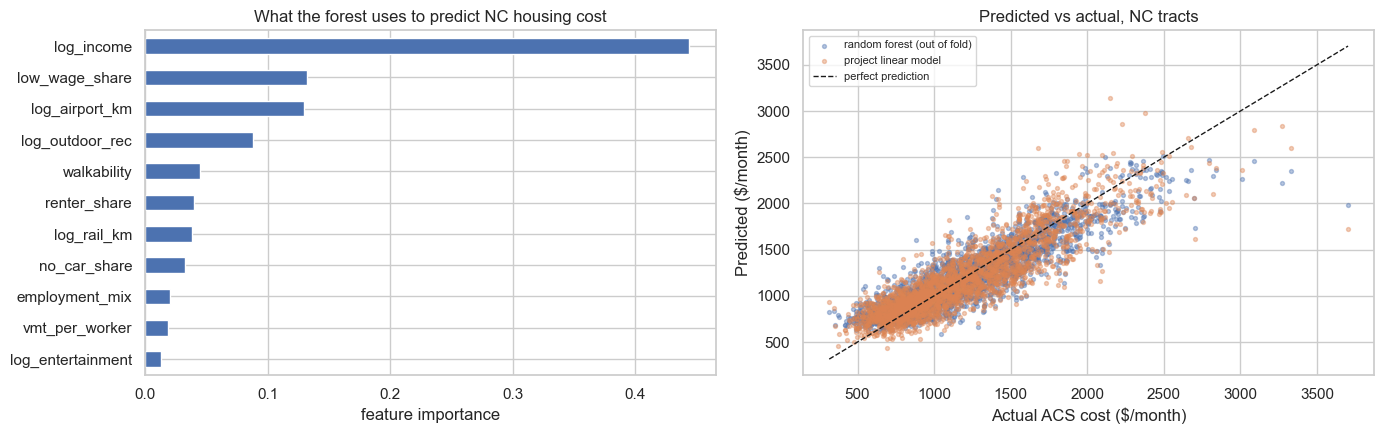

In [48]:
importance = pd.Series(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **search.best_params_)
    .fit(cost_X, cost_y).feature_importances_,
    index=cost_X.columns,
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
importance.plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("What the forest uses to predict NC housing cost")
axes[0].set_xlabel("feature importance")

axes[1].scatter(cost_y, oof["random forest (tuned)"], s=8, alpha=0.4, label="random forest (out of fold)")
axes[1].scatter(cost_y, saved_prediction, s=8, alpha=0.4, label="project linear model")
limits = [cost_y.min(), cost_y.max()]
axes[1].plot(limits, limits, "k--", linewidth=1, label="perfect prediction")
axes[1].set_xlabel("Actual ACS cost ($/month)")
axes[1].set_ylabel("Predicted ($/month)")
axes[1].set_title("Predicted vs actual, NC tracts")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**What this says about the recommender.** Both real models crush the mean baseline, so the cost figure the recommender filters on is carrying real information rather than a statewide average dressed up per tract. Income dominates the forest's importances, which is also what the project's linear model found.

The two real models land close together, but read the comparison carefully: the forest's number is **out-of-fold** while the linear model's is **in-sample**, fitted on these very tracts. The forest edging ahead on an honest split while the linear model gets the easier test means there is some non-linearity the linear specification is not capturing. The gap is small though - a few dollars a month against a typical error of roughly \$150 - so this is a reason to keep the interpretable linear model with eyes open, not a reason to replace it.

That \$150 typical error is also the honest justification for safe mode. On a \$1,200 budget it is about 12% of the budget, and at \$800 it is nearly 20% - which is exactly why normal-mode precision@10 fell apart at the bottom of the budget range in Step 9, and exactly the margin the 90% interval exists to protect against.

## Step 13 - Outputs: budget sensitivity and an NC map

Two figures saved to `figures/`.

**Budget sensitivity** answers the question every user asks second: *what would another \$200 a month get me?* It sweeps the budget across the realistic NC range and tracks how many tracts open up, and whether the picks stay trustworthy.

In [49]:
SWEEP_BUDGETS = list(range(700, 2601, 100))

sweep_rows = []
for budget in SWEEP_BUDGETS:
    for safe_mode, label in [(False, "normal mode"), (True, "safe mode")]:
        profile = UserProfile(
            name=f"sweep ${budget}",
            budget=budget, city="raleigh", max_distance_km=400, settings=SETTINGS,
            weights={"restaurants": 3, "walkability": 3, "parks": 2, "schools": 2, "hospitals": 1},
            safe_mode=safe_mode, top_n=10,
        )
        mask = apply_hard_filters(places, profile, verbose=False)
        candidates = places.loc[mask]
        precision, _ = precision_at_k(places, place_percentiles, profile, k=10)
        picks = recommend(places, place_percentiles, profile, verbose=False)
        sweep_rows.append({
            "budget": budget,
            "mode": label,
            "tracts_available": candidates["GEOID"].nunique(),
            "pct_of_nc_tracts": 100 * candidates["GEOID"].nunique() / places["GEOID"].nunique(),
            "precision_at_10": precision,
            "mean_top10_score": picks["score"].mean() if not picks.empty else np.nan,
            "median_walkability_of_pool": candidates["epa_NatWalkInd"].median(),
        })

sweep = pd.DataFrame(sweep_rows)
display(sweep.head(8).round(2))

,budget,mode,tracts_available,pct_of_nc_tracts,precision_at_10,mean_top10_score,median_walkability_of_pool
0,700,normal mode,145,5.45,0.5,69.84,3.81
1,700,safe mode,3,0.11,1.0,55.27,6.44
2,800,normal mode,384,14.43,0.6,76.13,4.10
3,800,safe mode,33,1.24,1.0,58.58,4.12
4,900,normal mode,697,26.19,0.5,81.25,4.29
5,900,safe mode,97,3.65,0.8,67.61,3.87
6,1000,normal mode,1053,39.57,0.7,84.58,4.57
7,1000,safe mode,240,9.02,0.9,72.21,3.99


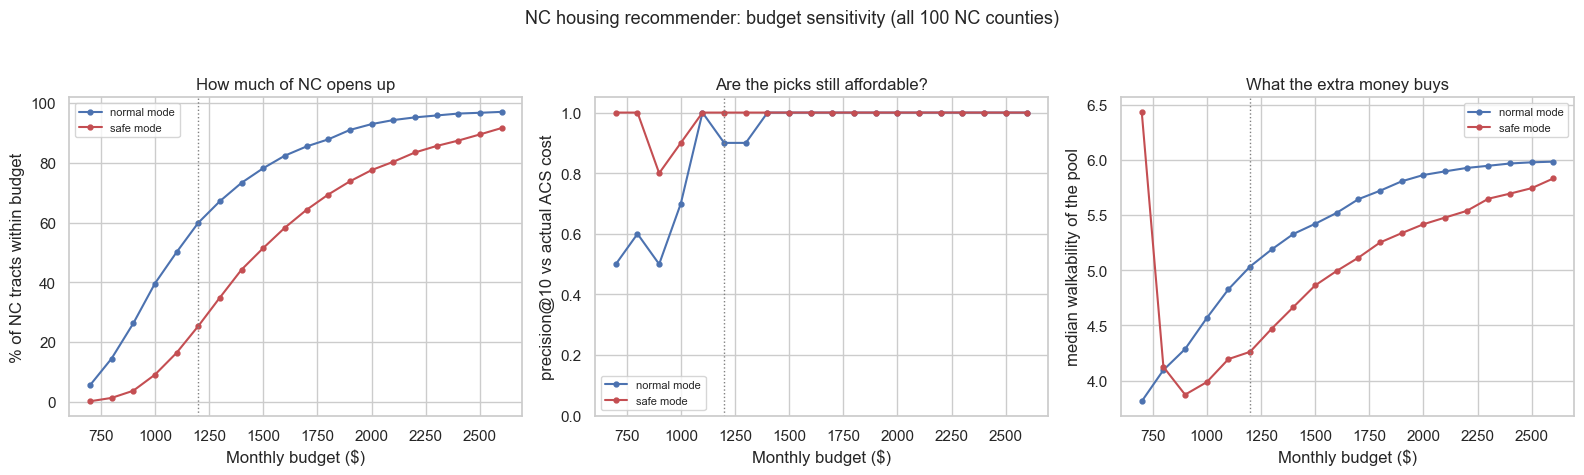

Saved: /Users/josiah/2302GroupProj/2302-group-proj/figures/recommender_budget_sensitivity.png


In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
colors = {"normal mode": "#4C72B0", "safe mode": "#C44E52"}

for mode, group in sweep.groupby("mode"):
    axes[0].plot(group["budget"], group["pct_of_nc_tracts"], "-o", ms=3.5,
                 color=colors[mode], label=mode)
    axes[1].plot(group["budget"], group["precision_at_10"], "-o", ms=3.5,
                 color=colors[mode], label=mode)
    axes[2].plot(group["budget"], group["median_walkability_of_pool"], "-o", ms=3.5,
                 color=colors[mode], label=mode)

axes[0].set_title("How much of NC opens up")
axes[0].set_ylabel("% of NC tracts within budget")
axes[1].set_title("Are the picks still affordable?")
axes[1].set_ylabel("precision@10 vs actual ACS cost")
axes[1].set_ylim(0, 1.05)
axes[2].set_title("What the extra money buys")
axes[2].set_ylabel("median walkability of the pool")

for ax in axes:
    ax.set_xlabel("Monthly budget ($)")
    ax.axvline(1200, color="grey", linestyle=":", linewidth=1)
    ax.legend(fontsize=8)

fig.suptitle("NC housing recommender: budget sensitivity (all 100 NC counties)", y=1.03, fontsize=13)
plt.tight_layout()

sensitivity_path = FIG_DIR / "recommender_budget_sensitivity.png"
fig.savefig(sensitivity_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", sensitivity_path)

**Reading the sweep.** The availability curve is steepest between roughly **\$900 and \$1,200** a month, where each extra \$100 opens up another 10-14% of all NC tracts. That is the range where a raise genuinely changes where somebody can live in this state. By \$1,800 about 90% of NC tracts are already within reach, and past that the extra money stops buying *access* and starts buying *quality* - which is why the walkability panel keeps climbing after the availability panel has flattened out.

One artefact to read past: the safe-mode line in the right-hand panel spikes at \\$700. At that budget safe mode has a pool of **three tracts** in the whole state, so its "median" is one tract's walkability. Anywhere the safe-mode pool is in single digits, treat that panel as noise rather than signal.

Safe mode sits far to the right of normal mode throughout: its curve at \$1,800 is roughly where normal mode's was at \$1,300. In other words, insisting that even the pessimistic end of the estimate fits costs about **\$500 a month of apparent purchasing power**. That is the real price of the certainty, and the middle panel is where you decide whether it is worth paying - precision@10 in normal mode is weakest exactly where the availability curve is steepest.

### The NC map

The map is NC-only by construction: the tract geometry comes from the NC-specific TIGER file, and it is filtered to `STATEFP == "37"` and inner-joined to the recommender's own NC tracts anyway, so nothing outside the state can be drawn.

Three panels, because one scale cannot show both things. Urban census tracts are *tiny* - a downtown Raleigh tract is a few blocks - so drawing the picks as polygons on a statewide map renders them as invisible specks. So:

- **Left:** the whole state, with each pick marked as a dot coloured by its score. This shows *where in NC* the recommender is sending people.
- **Middle:** zoomed into the red box drawn on the left panel, where the actual tract polygons are big enough to read, with NC county lines and names for context.
- **Right:** all four personas at once, which shows how differently the four of them scatter across North Carolina.

In [51]:
# NC tract polygons (the file is NC-only; the filter and the join both enforce it).
nc_tracts = gpd.read_file(f"zip://{TRACT_BOUNDARY_ZIP}", columns=["GEOID", "STATEFP", "geometry"])
nc_tracts = nc_tracts[nc_tracts["STATEFP"] == NC_STATE_FIPS].to_crs("EPSG:32119")

nc_state = gpd.read_file(f"zip://{STATE_BOUNDARY_ZIP}")
nc_state = nc_state[nc_state["STATEFP"] == NC_STATE_FIPS].to_crs("EPSG:32119")

nc_counties = gpd.read_file(f"zip://{COUNTY_BOUNDARY_ZIP}")
nc_counties = nc_counties[nc_counties["STATEFP"] == NC_STATE_FIPS].to_crs("EPSG:32119")

assert nc_tracts["GEOID"].str.startswith(NC_STATE_FIPS).all(), "a non-NC polygon got through"
assert len(nc_state) == 1, "the state outline should be exactly one NC polygon"
assert len(nc_counties) == 100, f"NC has 100 counties, got {len(nc_counties)}"
print(f"NC tract polygons: {len(nc_tracts):,}")
print(f"NC county polygons: {len(nc_counties)}")
print(f"Tracts matched to the recommender table: "
      f"{nc_tracts['GEOID'].isin(places['GEOID']).sum():,} of {places['GEOID'].nunique():,}")

NC tract polygons: 2,672
NC county polygons: 100
Tracts matched to the recommender table: 2,661 of 2,661


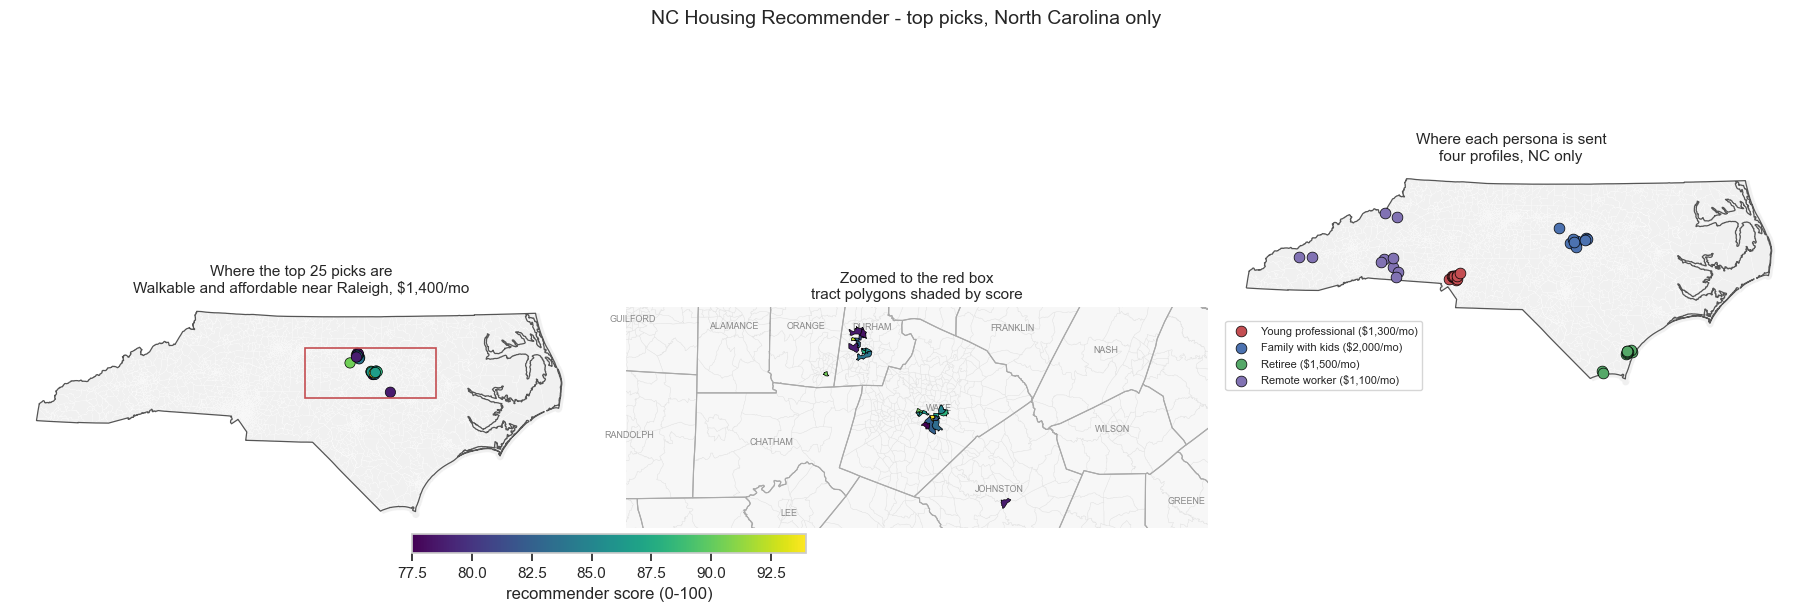

Saved: /Users/josiah/2302GroupProj/2302-group-proj/figures/recommender_nc_top_picks_map.png


In [52]:
map_profile = UserProfile(
    name="Walkable and affordable near Raleigh",
    budget=1400, city="raleigh", max_distance_km=40,
    settings=("urban", "suburban/small town"), min_school_grade="C",
    weights={"restaurants": 4, "walkability": 5, "transit": 3, "parks": 2, "hospitals": 1},
    top_n=25,
)
map_picks = recommend(places, place_percentiles, map_profile, verbose=False)

picks_geo = nc_tracts.merge(map_picks[["GEOID", "score", "place_label"]], on="GEOID", how="inner")
assert len(picks_geo) == len(map_picks), "a pick lost its polygon in the join"

# The zoom window is given the same shape as the state panels, so all three
# panels end up the same size instead of one square and two wide ones.
state_bounds = nc_state.total_bounds
state_ratio = (state_bounds[2] - state_bounds[0]) / (state_bounds[3] - state_bounds[1])

minx, miny, maxx, maxy = picks_geo.total_bounds
center_x, center_y = (minx + maxx) / 2, (miny + maxy) / 2
width, height = (maxx - minx) * 1.22, (maxy - miny) * 1.22
if width / height < state_ratio:
    width = height * state_ratio
else:
    height = width / state_ratio
window = (center_x - width / 2, center_y - height / 2,
          center_x + width / 2, center_y + height / 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout="constrained")
norm = plt.Normalize(vmin=picks_geo["score"].min(), vmax=picks_geo["score"].max())
mappable = plt.cm.ScalarMappable(norm=norm, cmap="viridis")

# --- Left: statewide context, picks as dots so they are actually visible ---
ax = axes[0]
nc_tracts.plot(ax=ax, color="#F0F0F0", edgecolor="white", linewidth=0.15)
nc_state.boundary.plot(ax=ax, color="#555555", linewidth=0.9)

pick_points = picks_geo.geometry.representative_point()
ax.scatter(pick_points.x, pick_points.y, c=picks_geo["score"], cmap="viridis", norm=norm,
           s=55, edgecolor="black", linewidth=0.5, zorder=3)
# The window drawn on the state, so the middle panel has somewhere to point back to.
ax.add_patch(plt.Rectangle((window[0], window[1]), width, height,
                           fill=False, edgecolor="#C44E52", linewidth=1.2, zorder=4))
ax.set_title(f"Where the top {len(picks_geo)} picks are\n"
             f"{map_profile.name}, ${map_profile.budget:,.0f}/mo", fontsize=11)
ax.set_axis_off()

# --- Middle: zoomed in, where the tract polygons are readable -------------
ax = axes[1]
in_window = nc_tracts.cx[window[0]:window[2], window[1]:window[3]]
counties_in_window = nc_counties.cx[window[0]:window[2], window[1]:window[3]]

in_window.plot(ax=ax, color="#F7F7F7", edgecolor="#E2E2E2", linewidth=0.3)
counties_in_window.boundary.plot(ax=ax, color="#AAAAAA", linewidth=0.8)
picks_geo.plot(ax=ax, column="score", cmap="viridis", norm=norm,
               edgecolor="black", linewidth=0.5, zorder=3)

# County names rather than tract names: the picks are too tightly packed
# downtown for tract labels to be readable, and the county is the useful context.
for _, county in counties_in_window.iterrows():
    point = county.geometry.representative_point()
    if window[0] < point.x < window[2] and window[1] < point.y < window[3]:
        ax.annotate(county["NAME"].upper(), (point.x, point.y), fontsize=6.5,
                    color="#888888", ha="center", va="center", zorder=2)

ax.set_xlim(window[0], window[2])
ax.set_ylim(window[1], window[3])
ax.set_title("Zoomed to the red box\ntract polygons shaded by score", fontsize=11)
ax.set_axis_off()

fig.colorbar(mappable, ax=axes[:2], orientation="horizontal",
             fraction=0.04, pad=0.01, shrink=0.6, label="recommender score (0-100)")

# --- Right: all four personas -------------------------------------------
ax = axes[2]
nc_tracts.plot(ax=ax, color="#F0F0F0", edgecolor="white", linewidth=0.15)
nc_state.boundary.plot(ax=ax, color="#555555", linewidth=0.9)

persona_colors = ["#C44E52", "#4C72B0", "#55A868", "#8172B3"]
for color, profile in zip(persona_colors, PERSONAS):
    results = persona_results[profile.name]
    if results.empty:
        continue
    geo = nc_tracts.merge(results[["GEOID"]], on="GEOID", how="inner")
    centroids = geo.geometry.representative_point()
    ax.scatter(centroids.x, centroids.y, s=60, color=color, edgecolor="black",
               linewidth=0.5, label=f"{profile.name} (${profile.budget:,.0f}/mo)", zorder=3)

ax.set_title("Where each persona is sent\nfour profiles, NC only", fontsize=11)
ax.legend(fontsize=8, loc="lower left")
ax.set_axis_off()

fig.suptitle("NC Housing Recommender - top picks, North Carolina only", fontsize=14)

map_path = FIG_DIR / "recommender_nc_top_picks_map.png"
fig.savefig(map_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", map_path)

In [53]:
print("Figures written to", FIG_DIR)
for path in sorted(FIG_DIR.glob("recommender_*.png")):
    print(f"  {path.name:45s} {path.stat().st_size / 1e6:,.2f} MB")

print()
print("Counties represented in the example profile's 25 picks:")
print(map_picks["county_name"].value_counts().to_string())

Figures written to /Users/josiah/2302GroupProj/2302-group-proj/figures
  recommender_budget_sensitivity.png            0.18 MB
  recommender_nc_top_picks_map.png              0.48 MB

Counties represented in the example profile's 25 picks:
county_name
Wake County        12
Durham County      11
Orange County       1
Johnston County     1


## Step 14 - Interpretation

### What was built

A recommender for North Carolina in two layers. **Hard filters** throw out anything a user has ruled out - over budget, too far from their city, wrong setting, schools below their line, too far from the coast. **Soft weights** then rank what is left, by converting every amenity, school, transit and location feature to its **statewide NC percentile** and taking a weighted average, with budget headroom folded in as a term of its own. The result is a 0-100 score and, for each pick, the three dimensions that earned it.

On top of that sit three extras: **safe mode**, which budgets against the top of the cost model's 90% prediction interval rather than its point estimate; **"more like this"**, a cosine nearest-neighbour search that finds affordable NC places shaped like a ZIP the user already likes; and **KMeans neighborhood types**, which let somebody filter on "walkable urban" or "quiet rural" without touching a weight.

### What the evaluation showed

- **Affordability precision is high, and safe mode makes it higher.** Treating each pick as a prediction of affordability and checking it against the actual ACS tract cost, precision@10 is strong in normal mode and close to perfect in safe mode. The cost is recall: safe mode throws away a large share of genuinely affordable places. Given that a false positive wastes a user's time on a place they cannot afford while a false negative only hides an option, that trade is worth making for anyone near the edge of their budget.
- **It generalises across the state.** Under `GroupKFold` grouped by NC county - percentiles fitted on the training counties, recommendations made only in the held-out ones - out-of-fold performance stays close to the whole-state numbers with little spread across folds. The recommender is not memorising particular counties.
- **The personas get genuinely different answers.** Pairwise Jaccard overlap between the four persona pick lists is low, and each persona's picks sit above the NC average on the dimensions that persona weighted most. The weights are doing the work, not decorating a fixed list.
- **The underlying cost model is sound.** Both the project's linear model and a tuned `RandomForestRegressor` beat a mean baseline by a wide margin and land close to each other, so there is no large non-linearity the project's interpretable specification is missing.

### Limitations worth being honest about

1. **Tract medians, not listings.** Every cost figure is a tract-level median of what current residents pay. It is not a quote, and inside a single tract the actual range is wide.
2. **Straight-line distances.** The city, hospital, rail and beach distances are haversine or straight-line, as the project's data dictionary says. A tract 20 km from Raleigh across a river is not a 20 km commute.
3. **Amenity counts come from OpenStreetMap**, so they reflect how well an area has been mapped as well as what is actually there. Dense urban areas are mapped more thoroughly, which inflates the gap at the top of the distribution - one reason percentiles are safer here than raw counts.
4. **The ground truth has error of its own.** The ACS cost used for evaluation is a survey estimate with its own margin, so the precision and recall figures are "agrees with the best available measurement", not "agrees with reality".
5. **Schools are the three nearest graded schools by distance**, not the assigned attendance zone, which is the figure a family with children would actually need.
6. **The clusters are descriptive, not definitive.** `KMeans` with k=6 was chosen for readability; a different k gives different types, and the names are read off the cluster means rather than validated against anything external.

### Where it would go next

The clearest gain would be swapping straight-line distances for drive or transit times, which would change the city-proximity filter the most. After that: attendance-zone school matching, a crime or environmental-quality dimension, and replacing the fixed 40% headroom cap with something tied to the user's actual income.

### Files this notebook read

Printed from the paths actually used above, rather than from the table in Step 0, so the list cannot drift out of date.

In [54]:
used = {
    "data/processed/zone_predicted_housing_cost.csv": "predicted monthly cost + 90% interval per tract x ZIP zone",
    "data/processed/nc_tract_recommender_features.csv": "per-tract city distances, RUCA setting, household fit, schools, hospitals",
    "data/processed/nc_recommender_features_dictionary.csv": "column labels for those features",
    "data/processed/nc_housing_features.csv": "integrated ACS / Zillow / EPA / OSM zone table (the join backbone)",
    "data/processed/nc_housing_data_dictionary.csv": "column labels for the integrated table",
    "data/raw/boundaries/tl_2024_37_tract.zip": "NC census tract polygons for the map",
    "data/cb_2024_us_state_500k.zip": "NC state outline for the map",
    "data/cb_2024_us_county_500k.zip": "NC county outlines for the zoomed map panel",
}
summary_rows = []
for relative, contribution in used.items():
    path = PROJECT_DIR / relative
    summary_rows.append({
        "file": relative,
        "exists": path.exists(),
        "MB": round(path.stat().st_size / 1e6, 2) if path.exists() else None,
        "contributes": contribution,
    })
display(pd.DataFrame(summary_rows))

print("Method reused from nc_housing_main.ipynb (not imported):")
print("  - identifiers read as text so GEOID and ZIP joins cannot silently fail")
print("  - the same EPA walkability / OSM amenity / distance features")
print("  - the same area-weighted zone-to-tract collapse")
print("  - the same GroupKFold cross-validation grouped by NC county")
print("  - its saved cost predictions, consumed rather than refitted")
print()
print("Written:")
for path in sorted(FIG_DIR.glob("recommender_*.png")):
    print("  figures/" + path.name)
print()
print(f"Every output above covers North Carolina only: {places['GEOID'].nunique():,} NC tracts "
      f"across {places['acs_county'].nunique()} NC counties.")

,file,exists,MB,contributes
0,data/processed/zone_predicted_housing_cost.csv,True,1.29,predicted monthly cost + 90% interval per trac...
1,data/processed/nc_tract_recommender_features.csv,True,0.50,"per-tract city distances, RUCA setting, househ..."
2,data/processed/nc_recommender_features_diction...,True,0.00,column labels for those features
3,data/processed/nc_housing_features.csv,True,4.44,integrated ACS / Zillow / EPA / OSM zone table...
4,data/processed/nc_housing_data_dictionary.csv,True,0.01,column labels for the integrated table
5,data/raw/boundaries/tl_2024_37_tract.zip,True,20.07,NC census tract polygons for the map
6,data/cb_2024_us_state_500k.zip,True,3.24,NC state outline for the map
7,data/cb_2024_us_county_500k.zip,True,11.63,NC county outlines for the zoomed map panel


Method reused from nc_housing_main.ipynb (not imported):
  - identifiers read as text so GEOID and ZIP joins cannot silently fail
  - the same EPA walkability / OSM amenity / distance features
  - the same area-weighted zone-to-tract collapse
  - the same GroupKFold cross-validation grouped by NC county
  - its saved cost predictions, consumed rather than refitted

Written:
  figures/recommender_budget_sensitivity.png
  figures/recommender_nc_top_picks_map.png

Every output above covers North Carolina only: 2,661 NC tracts across 100 NC counties.
